# Self-consistency of the strong LLM: analysis for the paper

**Study:** Implication-Weighted Data Selection for Financial QA — Protocol v1 (training-free).
**Run analysed:** Spec 3's self-consistency comparator, run on 25 October 2026 (01:24–06:35 UTC). Qwen3-235B-A22B-Instruct-2507 answered 3,000 pool items five times each.

This notebook documents:

- the self-consistency run: design, cost and measurement quality;
- its results;
- the preview of Spec 3's analysis A4 (agreement of Jev's reliability score R with self-consistency);
- a scoring issue the run revealed, which affects every accuracy measure in the study;
- **§9: the relation to Thread 2**, the consistency–accuracy dissociation paper (Zhang, Gondara & Novikova 2026, arXiv:2610.21128), with its quadrant analysis replicated on this run and extended with Jev's scores;
- **§10: Jev judging Qwen's own answers**, an exploratory, pre-specified follow-up: can an agreement-free judge catch the confident errors that self-consistency certifies?

**Purely descriptive.** It reads only frozen snapshots:

- `code/runs/self_consistency_2026-10-25/` (this run, with its call log);
- `code/runs/full_v2_2026-10-25/` (the pool and the primary Jev scores, battery v2);
- `code/runs/full_v0_2026-10-24/` (battery v0, the sensitivity analysis);
- `code/runs/jev_on_qwen_2026-10-25/` (§10: Jev's judgments of Qwen's answers).

It imports nothing from the pipeline, calls no API, and changes no code, configuration or output. Its only outputs are this notebook and `notebooks/figures/sc_*.pdf`.

## 0. Where self-consistency fits in the protocol

Protocol v1's E0 (measurement validity) asks, among other things, for **"agreement with 5-sample self-consistency of a strong LLM"**. Spec 3 makes this concrete.

**Comparator columns, on a 3,000-item stratified subsample:**
- `sc_acc`: the share of 5 `reason`-format samples that are correct;
- `sc_modal_share`: the share of samples agreeing with the most common answer.

**Analysis A4:**
- ρ(R, `sc_acc`);
- the AUROC of R for predicting whether the strong LLM's most common answer is correct.

**Role for the thesis.** R is meant to be P(datum is true). A4 asks whether Jev's R tracks something a strong model's own behaviour also reflects: a strong model reaching the gold answer consistently is weak evidence that the label is well-supported by the context. A4 is **not a gate** and has no pre-registered threshold. It is part of the E0 picture, alongside A1 (R against constructed wrong answers), which carries gate D1 and H1.

**What self-consistency is not:**
- It is not ground truth: every original's gold answer is verified by execution.
- It is not the base model's difficulty: that is `acc`, from OLMo 3 in Spec 2.

`sc_acc` measures how reliably a much stronger model reproduces the gold answer.

## 1. Setup, integrity and provenance

In [1]:
import hashlib
import json
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from scipy import stats
from sklearn.metrics import roc_auc_score

CODE = Path.cwd().parent / "code"
SC_DIR = CODE / "runs" / "self_consistency_2026-10-25"
V2_DIR = CODE / "runs" / "full_v2_2026-10-25"
V0_DIR = CODE / "runs" / "full_v0_2026-10-24"
FIG_DIR = Path.cwd() / "figures"
FIG_DIR.mkdir(exist_ok=True)
N_BOOT = 2000
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})


def verify(folder):
    for line in (folder / "SHA256SUMS").read_text().splitlines():
        digest, rel = line.split(maxsplit=1)
        if hashlib.sha256((folder / rel).read_bytes()).hexdigest() != digest:
            return False
    return True

JQ_DIR = CODE / "runs" / "jev_on_qwen_2026-10-25"
for d in (SC_DIR, V2_DIR, V0_DIR, JQ_DIR):
    print(f"{d.name:28s} checksums verified: {verify(d)}")

self_consistency_2026-10-25  checksums verified: True
full_v2_2026-10-25           checksums verified: True
full_v0_2026-10-24           checksums verified: True
jev_on_qwen_2026-10-25       checksums verified: True


In [2]:
cfg = yaml.safe_load((SC_DIR / "strong_config.yaml").read_text())
sc_cfg = cfg["self_consistency"]
print("model.strong:", cfg["version"], "via OpenRouter", cfg["name"], "| provider", cfg["provider"]["order"],
      "| fallbacks:", cfg["provider"]["allow_fallbacks"])
print("sampling (P5, owner decision):", {k: sc_cfg[k] for k in ("n_samples", "temperature", "top_p", "top_k", "min_p", "max_tokens")},
      "| sample seed = stable_seed(global_seed, item_id, 'sc', k)")

sub = pd.read_parquet(SC_DIR / "data" / "sc_subsample.parquet")
sc = pd.read_parquet(SC_DIR / "scores" / "self_consistency.parquet")
smp = pd.read_parquet(SC_DIR / "scores" / "sc_samples.parquet")
calls = pd.read_parquet(SC_DIR / "scores" / "sc_call_log.parquet")
pool = pd.read_parquet(V2_DIR / "data" / "pool.parquet")
items = pool.set_index("item_id")
QMAP = {("orig", "q1"): "q1", ("orig", "q2"): "q2", ("orig", "q3"): "q3",
        ("para", "q1"): "q1p", ("para", "q2"): "q2p", ("para", "q3"): "q3p"}


def jev(run_dir):
    s = pd.read_parquet(run_dir / "scores" / "jev_scores.parquet").set_index("item_id")
    long = pd.read_parquet(run_dir / "scores" / "jev_scores_long.parquet")
    q = long.assign(qid=[QMAP[(b, x)] for b, x in zip(long["battery"], long["question"])]) \
            .pivot(index="item_id", columns="qid", values="p_yes")
    return s.join(q)

j2, j0 = jev(V2_DIR), jev(V0_DIR)
df = (sc.merge(sub, on="item_id")
        .join(items[["source_answer_type", "gold_answer", "gold_value", "scale", "qa_tokens"]], on="item_id")
        .join(j2[["R", "I", "R_para", "I_para", "q3"]], on="item_id")
        .join(j0[["I"]].rename(columns={"I": "I_v0"}), on="item_id"))
df["I_Q3"] = df["q3"]
print(f"subsample items {len(sub):,}; scored {len(sc):,}; samples {len(smp):,}; Qwen calls logged {len(calls):,}")

model.strong: Qwen/Qwen3-235B-A22B-Instruct-2507 via OpenRouter qwen/qwen3-235b-a22b-2507 | provider ['deepinfra/fp8'] | fallbacks: False
sampling (P5, owner decision): {'n_samples': 5, 'temperature': 0.7, 'top_p': 0.8, 'top_k': 20, 'min_p': 0.0, 'max_tokens': 512} | sample seed = stable_seed(global_seed, item_id, 'sc', k)


subsample items 3,000; scored 3,000; samples 15,000; Qwen calls logged 15,000


## 2. Subsample design

Spec 3 draws **1,500 originals per dataset, stratified by `answer_type` and by R quintile**. R quintiles are computed within each dataset on the primary R, so that agreement with R can be estimated across its whole range. Negatives are excluded: the run measures the strong model on true labels.

The tables compare the subsample's strata with the full pool's. Proportional allocation makes them match up to rounding.

In [3]:
orig = pool[(pool["split"] == "pool") & ~pool["is_derived"]].set_index("item_id").join(j2[["R"]])
orig["r_quintile"] = orig.groupby("dataset")["R"].transform(lambda r: pd.qcut(r.rank(method="first"), 5, labels=False) + 1)
rows = []
for ds in ("finqa", "tatqa"):
    o = orig[orig["dataset"] == ds]
    s = df[df["dataset"] == ds]
    for (at, q), n_pool in o.groupby(["answer_type", "r_quintile"]).size().items():
        n_sub = int(((s["answer_type"] == at) & (s["r_quintile"] == q)).sum())
        rows.append({"dataset": ds, "answer_type": at, "R quintile": q, "pool": n_pool, "pool %": n_pool / len(o) * 100,
                     "subsample": n_sub, "subsample %": n_sub / len(s) * 100})
strata = pd.DataFrame(rows).set_index(["dataset", "answer_type", "R quintile"])
display(strata.round(1))
print("max |subsample % − pool %| across strata:", round((strata["subsample %"] - strata["pool %"]).abs().max(), 2), "points")
print("R range per quintile (FinQA):", orig[orig["dataset"] == "finqa"].groupby("r_quintile")["R"].agg(["min", "max"]).round(2).to_dict("index"))

pool  pool %  subsample  subsample %
dataset answer_type R quintile                                      
finqa   arith       1.0         1207    19.6        295         19.7
                    2.0         1204    19.6        294         19.6
                    3.0         1186    19.3        290         19.3
                    4.0         1173    19.1        286         19.1
                    5.0         1190    19.4        291         19.4
        lookup      1.0           22     0.4          5          0.3
                    2.0           24     0.4          6          0.4
                    3.0           43     0.7         10          0.7
                    4.0           55     0.9         13          0.9
                    5.0           39     0.6         10          0.7
tatqa   arith       1.0         1751    13.3        200         13.3
                    2.0         1246     9.5        143          9.5
                    3.0          707     5.4         81          5.4
                    4.0          741     5.6         85          5.7
                    5.0         1343    10.2        154         10.3
        lookup      1.0          872     6.6        100          6.7
                    2.0         1377    10.5        157         10.5
                    3.0         1916    14.6        219         14.6
                    4.0         1882    14.3        215         14.3
                    5.0         1280     9.8        146          9.7

max |subsample % − pool %| across strata: 0.04 points
R range per quintile (FinQA): {1.0: {'min': 0.0, 'max': 0.54}, 2.0: {'min': 0.54, 'max': 0.89}, 3.0: {'min': 0.89, 'max': 0.96}, 4.0: {'min': 0.96, 'max': 0.98}, 5.0: {'min': 0.98, 'max': 1.0}}


## 3. The run: cost, length and measurement quality

Every call was pinned to DeepInfra's FP8 deployment of Qwen3-235B-A22B-Instruct-2507, with no provider fallback, and each response's provider was checked. The `reason` format asks the model to reason briefly and end with `Answer: <value>`. An answer is "unparsed" when no answer line and, for arithmetic items, no final number can be extracted. Spec 2 caps unparsed samples at 5% overall and 10% per dataset for the base model; the same bar is applied here.

In [4]:
c = calls
t0, t1 = pd.to_datetime(c["at"]).min(), pd.to_datetime(c["at"]).max()
run = pd.Series({
    "calls": len(c), "providers": ", ".join(sorted(c["provider"].unique())), "total cost ($)": round(c["cost"].sum(), 2),
    "input tokens (M)": round(c["prompt_tokens"].sum() / 1e6, 2), "output tokens (M)": round(c["completion_tokens"].sum() / 1e6, 2),
    "mean prompt tokens": round(c["prompt_tokens"].mean()), "mean completion tokens": round(c["completion_tokens"].mean()),
    "median completion tokens": int(c["completion_tokens"].median()),
    "share at the 512-token cap": f"{(c['completion_tokens'] >= sc_cfg['max_tokens']).mean():.1%}",
    "wall-clock (h)": round((t1 - t0).total_seconds() / 3600, 2), "cost per item ($)": round(c["cost"].sum() / len(sub), 5),
})
display(run.to_frame("value"))
x = smp.join(items[["dataset", "answer_type", "source_answer_type"]], on="item_id")
unp = x.groupby(["dataset", "answer_type"])["answer"].apply(lambda a: a.isna().mean() * 100).rename("unparsed %")
display(unp.to_frame().round(2))
print(f"unparsed overall {x['answer'].isna().mean():.2%} (bar 5%); by dataset:",
      x.groupby("dataset")["answer"].apply(lambda a: f"{a.isna().mean():.2%}").to_dict(), "(bar 10%)")

,value
calls,15000
providers,DeepInfra
total cost ($),2.23
input tokens (M),12.13
output tokens (M),2.07
mean prompt tokens,809
mean completion tokens,138
median completion tokens,125
share at the 512-token cap,1.7%
wall-clock (h),5.19


unparsed %
dataset answer_type            
finqa   arith              0.34
        lookup             1.36
tatqa   arith              0.03
        lookup             0.96

unparsed overall 0.46% (bar 5%); by dataset: {'finqa': '0.37%', 'tatqa': '0.55%'} (bar 10%)


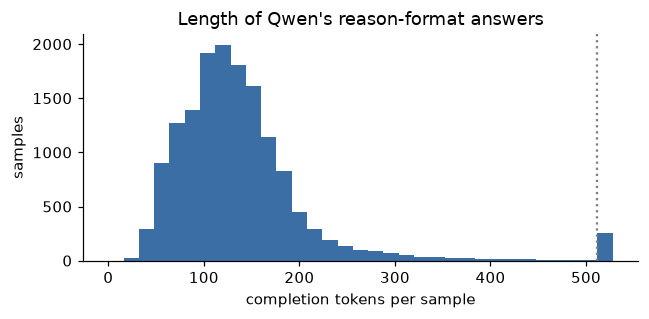

In [5]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(c["completion_tokens"], bins=np.arange(0, 530, 16), color="#3b6ea5")
ax.axvline(sc_cfg["max_tokens"], ls=":", color="grey")
ax.set_xlabel("completion tokens per sample")
ax.set_ylabel("samples")
ax.set_title("Length of Qwen's reason-format answers")
fig.tight_layout()
fig.savefig(FIG_DIR / "sc_completion_length.pdf", bbox_inches="tight")
plt.show()

**Findings.**
- **Cheap and fast.** 15,000 calls cost $2.23, about $0.0007 per item, and took about 5 hours at 8 parallel requests. Answers were short (median 125 tokens), and only 1.7% reached the 512-token cap.
- **Extraction is not a problem.** Under half a percent of samples have no extractable answer, far below the 5% bar. Format failures therefore cannot masquerade as low agreement.
- **Operational note.** A first attempt with 16 parallel requests was stopped by OpenRouter's rate limit after 33 calls. Those responses were cached and reused, so the total is exactly 15,000 calls.

## 4. Results as scored by the pipeline

The pipeline scores a sample as correct when its extracted answer matches the gold under `answers_match`: numeric answers with tolerance, text answers after normalisation, multi-span answers as sets. §6 shows that this scoring is too strict for one stratum.

In [6]:
by = df.groupby(["dataset", "answer_type"]).agg(items=("item_id", "size"), sc_acc=("sc_acc", "mean"),
                                                modal_share=("sc_modal_share", "mean"), modal_correct=("modal_correct", "mean"),
                                                all_5_correct=("sc_acc", lambda s: (s == 1).mean()),
                                                none_correct=("sc_acc", lambda s: (s == 0).mean()))
by.loc[("all", ""), :] = [len(df), df["sc_acc"].mean(), df["sc_modal_share"].mean(), df["modal_correct"].mean(),
                          (df["sc_acc"] == 1).mean(), (df["sc_acc"] == 0).mean()]
display(by.astype({"items": int}))
display(df.groupby(["dataset", "source_answer_type"])["sc_acc"].agg(["mean", "size"]).round(3)
          .rename(columns={"mean": "sc_acc", "size": "items"}))

items  sc_acc  modal_share  modal_correct  all_5_correct  \
dataset answer_type                                                             
finqa   arith         1456   0.729        0.941          0.738          0.672   
        lookup          44   0.923        0.959          0.932          0.841   
tatqa   arith          663   0.864        0.956          0.870          0.810   
        lookup         837   0.587        0.861          0.588          0.552   
all                   3000   0.722        0.922          0.728          0.672   

                     none_correct  
dataset answer_type                
finqa   arith               0.226  
        lookup              0.023  
tatqa   arith               0.094  
        lookup              0.380  
all                         0.237

sc_acc  items
dataset source_answer_type               
finqa   add                  0.568    113
        divide               0.776    979
        greater              0.926     38
        multiply             0.571     70
        subtract             0.632    256
        table_average        0.968     25
        table_max            0.860     10
        table_min            0.800      5
        table_sum            0.950      4
tatqa   arithmetic           0.862    627
        count                0.906     36
        multi-span           0.539    214
        span                 0.603    623

consistent but wrong (modal share ≥ 0.8 and modal answer wrong): 18.0% of items (FinQA 19.0%, TAT-QA 17.0%)


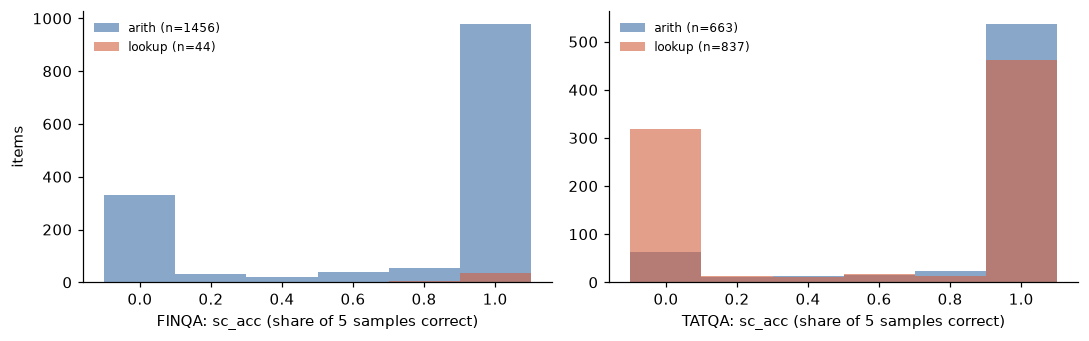

In [7]:
cons_wrong = (df["sc_modal_share"] >= 0.8) & ~df["modal_correct"]
print(f"consistent but wrong (modal share ≥ 0.8 and modal answer wrong): {cons_wrong.mean():.1%} of items "
      f"(FinQA {cons_wrong[df['dataset'] == 'finqa'].mean():.1%}, TAT-QA {cons_wrong[df['dataset'] == 'tatqa'].mean():.1%})")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, ds in zip(axes, ("finqa", "tatqa")):
    g = df[df["dataset"] == ds]
    for at, col in (("arith", "#3b6ea5"), ("lookup", "#d1603d")):
        v = g.loc[g["answer_type"] == at, "sc_acc"]
        ax.hist(v, bins=np.linspace(-0.1, 1.1, 7), alpha=0.6, color=col, label=f"{at} (n={len(v)})")
    ax.set_xlabel(f"{ds.upper()}: sc_acc (share of 5 samples correct)")
    ax.legend(frameon=False, fontsize=8)
axes[0].set_ylabel("items")
fig.tight_layout()
fig.savefig(FIG_DIR / "sc_acc_distribution.pdf", bbox_inches="tight")
plt.show()

**Findings.**
- **Highly consistent model.** The modal share averages 0.92: Qwen usually gives the same answer in all five samples, so `sc_acc` is close to binary per item (all five right, or none).
- **As scored by the pipeline, accuracy is high but uneven.** It is highest on FinQA lookup and TAT-QA arithmetic, and lowest on **TAT-QA lookup (0.59)**, especially multi-span answers. §6 shows that much of this low value is a scoring artefact, not model error.
- **Consistent but wrong:** 18% of items (FinQA 19%, TAT-QA 17%) are answered consistently but wrongly (modal share ≥ 0.8 with a wrong modal answer). This mirrors the protocol's CBI notion ("consistent but incorrect"), here measured for the strong model rather than the base model. Part of it is the scoring artefact of §6.

## 5. A4 preview: does Jev's R agree with self-consistency?

This is Spec 3's A4, computed here outside the analysis code:

- **ρ(R, `sc_acc`)**, with a Fisher-z 95% interval;
- **AUROC of R** for predicting whether Qwen's modal answer is correct, with a bootstrap interval.

Both are shown overall, by dataset and by answer type, and also for the paraphrased R′. For context, the same correlations are given for I under the three definitions the study reports: primary v2, v0 sensitivity, and Q3-only robustness.

In [8]:
def rho_ci(x, y):
    r = stats.spearmanr(x, y)[0]
    z, se = np.arctanh(r), 1 / np.sqrt(len(x) - 3)
    return r, np.tanh(z - 1.96 * se), np.tanh(z + 1.96 * se)


def auc_ci(y, s, n=N_BOOT, seed=0):
    y, s = np.asarray(y, bool), np.asarray(s, float)
    if y.all() or not y.any():
        return np.nan, np.nan, np.nan
    g = np.random.default_rng(seed)
    reps = []
    for _ in range(n):
        i = g.integers(0, len(y), len(y))
        if y[i].all() or not y[i].any():
            continue
        reps.append(roc_auc_score(y[i], s[i]))
    return roc_auc_score(y, s), *np.percentile(reps, [2.5, 97.5])


def fmt(t):
    return f"{t[0]:.3f} [{t[1]:.3f}, {t[2]:.3f}]"


def a4(frame, acc_col="sc_acc", modal_col="modal_correct"):
    out = {}
    for label, g in [("all", frame), ("FinQA", frame[frame["dataset"] == "finqa"]), ("TAT-QA", frame[frame["dataset"] == "tatqa"]),
                     ("arith", frame[frame["answer_type"] == "arith"]), ("lookup", frame[frame["answer_type"] == "lookup"])]:
        out[label] = {"n": len(g), "ρ(R, sc_acc)": fmt(rho_ci(g["R"], g[acc_col])),
                      "AUROC of R → modal correct": fmt(auc_ci(g[modal_col], g["R"])),
                      "ρ(R′, sc_acc)": fmt(rho_ci(g["R_para"], g[acc_col]))}
    return pd.DataFrame(out).T

a4_em = a4(df)
with pd.option_context("display.max_colwidth", None):
    display(a4_em)
idef = pd.DataFrame({name: {"ρ(I, sc_acc)": fmt(rho_ci(df[col], df["sc_acc"])),
                            "AUROC of I → modal correct": fmt(auc_ci(df["modal_correct"], df[col]))}
                     for name, col in (("I (v2, primary)", "I"), ("I_v0 (sensitivity)", "I_v0"), ("I_Q3 (robustness)", "I_Q3"))}).T
display(idef)

,n,"ρ(R, sc_acc)",AUROC of R → modal correct,"ρ(R′, sc_acc)"
all,3000,"0.301 [0.268, 0.333]","0.676 [0.653, 0.699]","0.268 [0.234, 0.301]"
FinQA,1500,"0.551 [0.515, 0.585]","0.845 [0.820, 0.869]","0.559 [0.523, 0.593]"
TAT-QA,1500,"0.126 [0.076, 0.175]","0.568 [0.537, 0.599]","0.104 [0.053, 0.153]"
arith,2119,"0.512 [0.480, 0.542]","0.837 [0.815, 0.859]","0.518 [0.486, 0.548]"
lookup,881,"0.056 [-0.010, 0.122]","0.526 [0.488, 0.566]","0.148 [0.083, 0.212]"


,"ρ(I, sc_acc)",AUROC of I → modal correct
"I (v2, primary)","0.241 [0.207, 0.275]","0.639 [0.617, 0.663]"
I_v0 (sensitivity),"0.294 [0.261, 0.327]","0.676 [0.653, 0.698]"
I_Q3 (robustness),"0.191 [0.156, 0.225]","0.618 [0.596, 0.640]"


sc_acc  modal_correct  R_median    n
dataset r_quintile                                      
finqa   1            0.277          0.280      0.23  300
        2            0.696          0.717      0.78  300
        3            0.852          0.860      0.93  300
        4            0.903          0.910      0.97  299
        5            0.945          0.950      0.99  301
tatqa   1            0.605          0.610      0.82  300
        2            0.731          0.730      0.96  300
        3            0.734          0.743      0.98  300
        4            0.699          0.703      0.99  300
        5            0.777          0.777      0.99  300

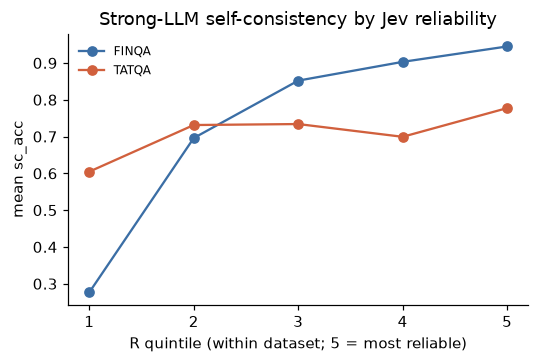

In [9]:
q = df.groupby(["dataset", "r_quintile"]).agg(sc_acc=("sc_acc", "mean"), modal_correct=("modal_correct", "mean"),
                                              R_median=("R", "median"), n=("item_id", "size"))
display(q.round(3))
fig, ax = plt.subplots(figsize=(5, 3.4))
for ds, col in (("finqa", "#3b6ea5"), ("tatqa", "#d1603d")):
    g = q.loc[ds]
    ax.plot(g.index, g["sc_acc"], marker="o", color=col, label=ds.upper())
ax.set_xticks([1, 2, 3, 4, 5])
ax.set_xlabel("R quintile (within dataset; 5 = most reliable)")
ax.set_ylabel("mean sc_acc")
ax.set_title("Strong-LLM self-consistency by Jev reliability")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "sc_acc_by_R_quintile.pdf", bbox_inches="tight")
plt.show()

**Findings.**
- **Overall, R agrees moderately with self-consistency:** ρ(R, `sc_acc`) = 0.30 [0.27, 0.33], and the AUROC of R for a correct modal answer is 0.68 [0.65, 0.70].
- **The overall number hides a strong dataset difference.**
  - **FinQA:** ρ = 0.55 and AUROC 0.84. Mean `sc_acc` climbs steadily from 0.28 in the lowest R quintile to 0.95 in the highest.
  - **TAT-QA:** ρ = 0.13 and AUROC 0.57, and the quintile trend is weak and not monotone.
  - **By answer type:** arithmetic items agree well (ρ = 0.51), lookup items hardly at all (ρ = 0.06).
- **Two reasons for the TAT-QA weakness:**
  - **R is squeezed near 1 in TAT-QA.** Quintiles 2–5 all have median R of 0.96–0.99, so R has little room to rank items.
  - **TAT-QA's lookup answers are scored too strictly (§6),** which adds noise to `sc_acc` exactly where agreement is weakest.
- **Why agreement is moderate at all:** R judges whether the stated, verified answer is supported by the context. `sc_acc` measures whether a strong model reproduces that answer on its own, which also depends on difficulty and on scoring.
- **The paraphrased R′ gives the same picture** (overall 0.27, FinQA 0.56), so the result does not depend on Q1's wording.
- **I under three definitions.** Primary I correlates less with `sc_acc` (ρ = 0.24) than R does, as intended. **v0's I correlates more (0.29) and Q3-only I less (0.19).** That fits v0's determinacy question carrying a correctness component, which battery v2 removed.

## 6. A scoring issue: span answers are judged too strictly

For text-span answers (TAT-QA lookup), exact matching after normalisation counts many correct answers as wrong. A random sample of mismatches shows four kinds:

1. **Numerically equivalent spans in another format:** gold `NT$3,815 million`, answer `3,815,000,000`.
2. **The key value from a longer gold span:** gold "aggregate intrinsic value of $239 million based on…", answer `$239 million`.
3. **Multi-span answers with joining words or years:** `$187.2 million in 2019 and $201.2 million in 2018`.
4. **Near-verbatim paraphrases of long text spans.**

Below, each sample is re-scored three more ways:

- **numeric equivalence:** every number in the answer equals a number in the gold, with scale words applied;
- **token-F1 ≥ 0.8:** near-verbatim;
- **token-F1 ≥ 0.5.**

Token-F1 is the second metric in TAT-QA's official evaluation, next to exact match. These re-scorings are diagnostics, not the pipeline's metric.

In [10]:
SCALE = {"thousand": 1e3, "million": 1e6, "billion": 1e9}


def toks(s):
    return re.findall(r"[a-z0-9]+(?:\.[0-9]+)?", (s or "").lower())


def token_f1(p, g):
    p, g = toks(p), toks(g)
    if not p or not g:
        return 0.0
    common = sum((Counter(p) & Counter(g)).values())
    if common == 0:
        return 0.0
    pr, rc = common / len(p), common / len(g)
    return 2 * pr * rc / (pr + rc)


def numbers(s):
    out = []
    for m in re.finditer(r"-?\d[\d,]*\.?\d*", s or ""):
        try:
            v = float(m.group().replace(",", "").rstrip("."))
        except ValueError:
            continue
        tail = (s[m.end():m.end() + 12] or "").strip().lower()
        mult = next((k for k in SCALE if tail.startswith(k)), None)
        out.append(v * (SCALE[mult] if mult else 1))
    return out


def numeric_equivalent(p, g, scale):
    gn, pn = numbers(g), numbers(p)
    if not gn or not pn or len(pn) < len(gn):
        return False
    targets = set(gn) | ({v * SCALE[scale] for v in gn} if scale in SCALE else set())
    return all(any(abs(v - w) <= 1e-6 * max(1.0, abs(w)) for w in targets) for v in pn)


s2 = smp.join(items[["dataset", "answer_type", "source_answer_type", "gold_answer", "scale"]], on="item_id")
s2["f1"] = [1.0 if c else token_f1(a, g) for a, g, c in zip(s2["answer"], s2["gold_answer"], s2["correct"])]
s2["numeq"] = [bool(c) or (a is not None and numeric_equivalent(a, g, sc_ or ""))
               for a, g, sc_, c in zip(s2["answer"], s2["gold_answer"], s2["scale"], s2["correct"])]
s2["c_num"] = s2["numeq"]
s2["c_f1_08"] = s2["numeq"] | (s2["f1"] >= 0.8)
s2["c_f1_05"] = s2["numeq"] | (s2["f1"] >= 0.5)
rescore = s2.groupby(["dataset", "answer_type"]).agg(exact_match=("correct", "mean"), plus_numeric=("c_num", "mean"),
                                                     plus_F1_08=("c_f1_08", "mean"), plus_F1_05=("c_f1_05", "mean"),
                                                     mean_token_F1=("f1", "mean"))
display((rescore * 100).round(1).rename_axis(columns="% of samples correct"))
w = s2[(s2["dataset"] == "tatqa") & (s2["answer_type"] == "lookup") & ~s2["correct"] & s2["answer"].notna()]
print(f"TAT-QA lookup, parsed but scored wrong: {len(w):,} samples; numerically equivalent {w['numeq'].mean():.1%}; "
      f"token-F1 ≥ 0.8 {(w['f1'] >= 0.8).mean():.1%}; ≥ 0.5 {(w['f1'] >= 0.5).mean():.1%}; F1 = 0 {(w['f1'] == 0).mean():.1%}")

% of samples correct  exact_match  plus_numeric  plus_F1_08  plus_F1_05  \
dataset answer_type                                                       
finqa   arith                72.9          72.9        74.5        74.5   
        lookup               92.3          92.3        94.1        94.1   
tatqa   arith                86.4          86.5        87.4        89.4   
        lookup               58.7          66.1        74.3        86.4   

% of samples correct  mean_token_F1  
dataset answer_type                  
finqa   arith                  74.5  
        lookup                 94.1  
tatqa   arith                  88.8  
        lookup                 81.3

TAT-QA lookup, parsed but scored wrong: 1,690 samples; numerically equivalent 18.5%; token-F1 ≥ 0.8 27.7%; ≥ 0.5 67.6%; F1 = 0 12.7%


In [11]:
pd.set_option("display.max_colwidth", 90)
ex = w.assign(kind=np.select([w["numeq"], w["f1"] >= 0.8, w["f1"] >= 0.5, w["f1"] == 0],
                             ["numeric equivalent", "near-verbatim (F1 ≥ 0.8)", "partial (F1 ≥ 0.5)", "no overlap"], "low overlap"))
examples = pd.concat([g.drop_duplicates("item_id").head(3) for _, g in ex.groupby("kind")])
display(examples[["kind", "source_answer_type", "gold_answer", "answer"]].reset_index(drop=True))

,kind,source_answer_type,gold_answer,answer
0,low overlap,span,"The Committee has approved Fixed Pay increases of 4% for the CEO and 3% for the CFO, e...",4%
1,low overlap,span,we excluded from the calculation of diluted loss per share 3.0 million shares and 4.6 ...,3.0 million shares in 2019 and 4.6 million shares in 2018
2,low overlap,multi-span,4.2 million; 11.7 million,$15.9 million
3,near-verbatim (F1 ≥ 0.8),multi-span,"2,072; 2,168 million","2,072 and 2,168"
4,near-verbatim (F1 ≥ 0.8),span,management’s best estimates of expected future costs to restore current leased premise...,AROs reflect management’s best estimates of expected future costs to restore current l...
5,near-verbatim (F1 ≥ 0.8),span,Restated for the adoption of IFRS 15 and change in accounting policy in respect of res...,The adoption of IFRS 15 and change in accounting policy in respect of research and dev...
6,no overlap,span,data centers and colocation business,$193 million
7,no overlap,span,"The Committee has approved Fixed Pay increases of 4% for the CEO and 3% for the CFO, e...","58,000"
8,no overlap,span,"28,815,258,178","454,870"
9,numeric equivalent,span,3 cents per share,3 cents


In [12]:
item_rs = s2.groupby("item_id").agg(sc_acc_num=("c_num", "mean"), sc_acc_f1=("c_f1_08", "mean"))
df2 = df.join(item_rs, on="item_id")
def modal_correct_lenient(col):
    return df2[col] >= 0.6   # majority of the 5 samples correct, as a lenient stand-in for the modal answer

df2["modal_num"] = modal_correct_lenient("sc_acc_num")
df2["modal_f1"] = modal_correct_lenient("sc_acc_f1")
comp = pd.DataFrame({
    "exact match (pipeline)": {"mean sc_acc": df2["sc_acc"].mean(), "TAT-QA lookup sc_acc": df2.loc[(df2["dataset"] == "tatqa") & (df2["answer_type"] == "lookup"), "sc_acc"].mean(),
                               "ρ(R, sc_acc)": stats.spearmanr(df2["R"], df2["sc_acc"])[0],
                               "AUROC of R → modal correct": roc_auc_score(df2["modal_correct"], df2["R"])},
    "+ numeric equivalence": {"mean sc_acc": df2["sc_acc_num"].mean(), "TAT-QA lookup sc_acc": df2.loc[(df2["dataset"] == "tatqa") & (df2["answer_type"] == "lookup"), "sc_acc_num"].mean(),
                              "ρ(R, sc_acc)": stats.spearmanr(df2["R"], df2["sc_acc_num"])[0],
                              "AUROC of R → modal correct": roc_auc_score(df2["modal_num"], df2["R"])},
    "+ numeric + token-F1 ≥ 0.8": {"mean sc_acc": df2["sc_acc_f1"].mean(), "TAT-QA lookup sc_acc": df2.loc[(df2["dataset"] == "tatqa") & (df2["answer_type"] == "lookup"), "sc_acc_f1"].mean(),
                                   "ρ(R, sc_acc)": stats.spearmanr(df2["R"], df2["sc_acc_f1"])[0],
                                   "AUROC of R → modal correct": roc_auc_score(df2["modal_f1"], df2["R"])},
})
display(comp.round(3))
print("Note: under the lenient scorings, 'modal correct' is approximated by a majority (≥ 3 of 5) of samples correct.")

,exact match (pipeline),+ numeric equivalence,+ numeric + token-F1 ≥ 0.8
mean sc_acc,0.722,0.743,0.776
TAT-QA lookup sc_acc,0.587,0.661,0.743
"ρ(R, sc_acc)",0.301,0.334,0.376
AUROC of R → modal correct,0.676,0.703,0.743


Note: under the lenient scorings, 'modal correct' is approximated by a majority (≥ 3 of 5) of samples correct.


**Findings.**
- **The low TAT-QA lookup score is mostly a scoring artefact.**
  - Exact match gives 58.7%.
  - Counting numerically equivalent spans raises it to about 66%.
  - Also counting near-verbatim answers (token-F1 ≥ 0.8) raises it to about 74%.
  - Mean token-F1, TAT-QA's official second metric, is 0.81.
  - Only about one in eight mismatches shares no words with the gold.
- **The other strata barely change.** Arithmetic answers are already compared numerically, and FinQA lookup answers are short.
- **Lenient scoring strengthens A4 rather than changing its direction.** ρ(R, `sc_acc`) rises from 0.30 (exact) to 0.33 (numeric equivalence) and 0.38 (also near-verbatim); the AUROC rises from 0.68 to 0.70 and 0.74. The strict scorer adds noise, mostly in TAT-QA lookup, which attenuates the agreement. The formal A4 should be reported under whichever scorer the owner adopts, with the others as sensitivity analyses.

**Why this matters beyond self-consistency.** The same matcher will score:

- **Spec 2's base-model accuracy `acc`:** the difficulty covariate in gate D2 and in the residualised-I condition (`top_I_resid`);
- **proxy C's test accuracy:** the outcome for H2–H6 under C.

A strict span scorer would make TAT-QA lookup items look harder than they are, and would add noise to the demonstration study. The protocol specifies "exact-match accuracy **with numeric tolerance**". Numeric equivalence for numeric spans therefore arguably belongs to the pre-registered metric, while token-F1 would be a separate robustness metric. **This is an open owner decision (implementation plan, blocking question 5), to settle before Spec 2's full run.** If the matcher changes, `sc_acc` can be re-scored from the cached samples at no API cost.

### 6b. Robustness analysis: token-F1 as an alternative scorer

This is the scoring set-up suggested for the paper (pending the owner's decision, blocking question 5). The three scorings are reported side by side, and A4 is re-run under each:

| Scoring | Role | Per-sample score | Per-item score |
|---|---|---|---|
| **Exact match** | current pipeline (`answers_match`) | 1 if the extracted answer matches the gold, else 0 | `sc_acc` = mean over the 5 samples |
| **Exact match + numeric equivalence** | suggested **primary** metric: "exact match with numeric tolerance", as the protocol specifies, extended to numeric spans | 1 if exact match, or if every number in the answer equals a gold number (scale words applied) | `sc_acc_num` = mean over the 5 samples |
| **Token-F1** | suggested **robustness** metric, TAT-QA's official second metric | 1 if exact or numeric match, else the token-level F1 between answer and gold | `sc_f1` = mean over the 5 samples (continuous) |

For the modal answer under the alternative scorings, "modal correct" is approximated by "at least 3 of the 5 samples correct" (numeric) or "mean token-F1 ≥ 0.5" (token-F1).

In [13]:
s2["score_f1"] = np.where(s2["c_num"], 1.0, s2["f1"])
per_item = s2.groupby("item_id").agg(sc_acc_num=("c_num", "mean"), sc_f1=("score_f1", "mean"))
d3 = df.drop(columns=[c for c in ("sc_acc_num", "sc_f1") if c in df.columns]).join(per_item, on="item_id")
d3["modal_num"] = d3["sc_acc_num"] >= 0.6
d3["modal_f1"] = d3["sc_f1"] >= 0.5
SCORERS = {"exact match (pipeline)": ("sc_acc", "modal_correct"),
           "exact + numeric (primary, suggested)": ("sc_acc_num", "modal_num"),
           "token-F1 (robustness, suggested)": ("sc_f1", "modal_f1")}
SUBSETS = [("all", d3), ("FinQA", d3[d3["dataset"] == "finqa"]), ("TAT-QA", d3[d3["dataset"] == "tatqa"]),
           ("arith", d3[d3["answer_type"] == "arith"]), ("lookup", d3[d3["answer_type"] == "lookup"]),
           ("TAT-QA lookup", d3[(d3["dataset"] == "tatqa") & (d3["answer_type"] == "lookup")])]
rows = []
for sname, (acc_col, modal_col) in SCORERS.items():
    for label, g in SUBSETS:
        rows.append({"scoring": sname, "subset": label, "n": len(g), "mean score": g[acc_col].mean(),
                     "ρ(R, score)": fmt(rho_ci(g["R"], g[acc_col])),
                     "AUROC of R → modal correct": fmt(auc_ci(g[modal_col], g["R"], n=1000)),
                     "ρ(R′, score)": f"{stats.spearmanr(g['R_para'], g[acc_col])[0]:.3f}"})
robust = pd.DataFrame(rows).set_index(["subset", "scoring"]).sort_index(level=0, sort_remaining=False)
order = [lbl for lbl, _ in SUBSETS]
robust = robust.reindex(order, level=0)
with pd.option_context("display.max_colwidth", None):
    display(robust)

n  mean score  \
subset        scoring                                                  
all           exact match (pipeline)                3000       0.722   
              exact + numeric (primary, suggested)  3000       0.743   
              token-F1 (robustness, suggested)      3000       0.804   
FinQA         exact match (pipeline)                1500       0.735   
              exact + numeric (primary, suggested)  1500       0.735   
              token-F1 (robustness, suggested)      1500       0.751   
TAT-QA        exact match (pipeline)                1500       0.709   
              exact + numeric (primary, suggested)  1500       0.751   
              token-F1 (robustness, suggested)      1500       0.858   
arith         exact match (pipeline)                2119       0.771   
              exact + numeric (primary, suggested)  2119       0.771   
              token-F1 (robustness, suggested)      2119       0.790   
lookup        exact match (pipeline)                 881       0.603   
              exact + numeric (primary, suggested)   881       0.674   
              token-F1 (robustness, suggested)       881       0.839   
TAT-QA lookup exact match (pipeline)                 837       0.587   
              exact + numeric (primary, suggested)   837       0.661   
              token-F1 (robustness, suggested)       837       0.834   

                                                              ρ(R, score)  \
subset        scoring                                                       
all           exact match (pipeline)                 0.301 [0.268, 0.333]   
              exact + numeric (primary, suggested)   0.334 [0.302, 0.366]   
              token-F1 (robustness, suggested)       0.387 [0.357, 0.417]   
FinQA         exact match (pipeline)                 0.551 [0.515, 0.585]   
              exact + numeric (primary, suggested)   0.552 [0.515, 0.586]   
              token-F1 (robustness, suggested)       0.568 [0.532, 0.601]   
TAT-QA        exact match (pipeline)                 0.126 [0.076, 0.175]   
              exact + numeric (primary, suggested)   0.151 [0.102, 0.201]   
              token-F1 (robustness, suggested)       0.197 [0.148, 0.245]   
arith         exact match (pipeline)                 0.512 [0.480, 0.542]   
              exact + numeric (primary, suggested)   0.512 [0.480, 0.543]   
              token-F1 (robustness, suggested)       0.532 [0.501, 0.562]   
lookup        exact match (pipeline)                0.056 [-0.010, 0.122]   
              exact + numeric (primary, suggested)   0.073 [0.007, 0.139]   
              token-F1 (robustness, suggested)       0.119 [0.053, 0.184]   
TAT-QA lookup exact match (pipeline)                 0.069 [0.002, 0.136]   
              exact + numeric (primary, suggested)   0.081 [0.013, 0.148]   
              token-F1 (robustness, suggested)       0.129 [0.062, 0.195]   

                                                   AUROC of R → modal correct  \
subset        scoring                                                           
all           exact match (pipeline)                     0.676 [0.653, 0.699]   
              exact + numeric (primary, suggested)       0.703 [0.679, 0.726]   
              token-F1 (robustness, suggested)           0.815 [0.792, 0.837]   
FinQA         exact match (pipeline)                     0.845 [0.818, 0.868]   
              exact + numeric (primary, suggested)       0.844 [0.818, 0.868]   
              token-F1 (robustness, suggested)           0.860 [0.834, 0.882]   
TAT-QA        exact match (pipeline)                     0.568 [0.538, 0.600]   
              exact + numeric (primary, suggested)       0.589 [0.557, 0.622]   
              token-F1 (robustness, suggested)           0.712 [0.668, 0.754]   
arith         exact match (pipeline)                     0.837 [0.816, 0.859]   
              exact + numeric (primary, suggested)       0.838 [0.816, 0.859]   
              token-

,exact match (pipeline),"exact + numeric (primary, suggested)","token-F1 (robustness, suggested)"
"ρ(I, score)",,,
"I (v2, primary)",0.241,0.281,0.306
I_v0 (sensitivity),0.294,0.341,0.381
I_Q3 (robustness),0.191,0.198,0.190


exact match (pipeline)  \
dataset r_quintile                           
finqa   1                            0.277   
        2                            0.696   
        3                            0.852   
        4                            0.903   
        5                            0.945   
tatqa   1                            0.605   
        2                            0.731   
        3                            0.734   
        4                            0.699   
        5                            0.777   

                    exact + numeric (primary, suggested)  \
dataset r_quintile                                         
finqa   1                                          0.277   
        2                                          0.696   
        3                                          0.852   
        4                                          0.903   
        5                                          0.946   
tatqa   1                                          0.623   
        2                                          0.779   
        3                                          0.782   
        4                                          0.757   
        5                                          0.815   

                    token-F1 (robustness, suggested)  
dataset r_quintile                                    
finqa   1                                      0.290  
        2                                      0.704  
        3                                      0.880  
        4                                      0.922  
        5                                      0.959  
tatqa   1                                      0.690  
        2                                      0.881  
        3                                      0.896  
        4                                      0.902  
        5                                      0.920

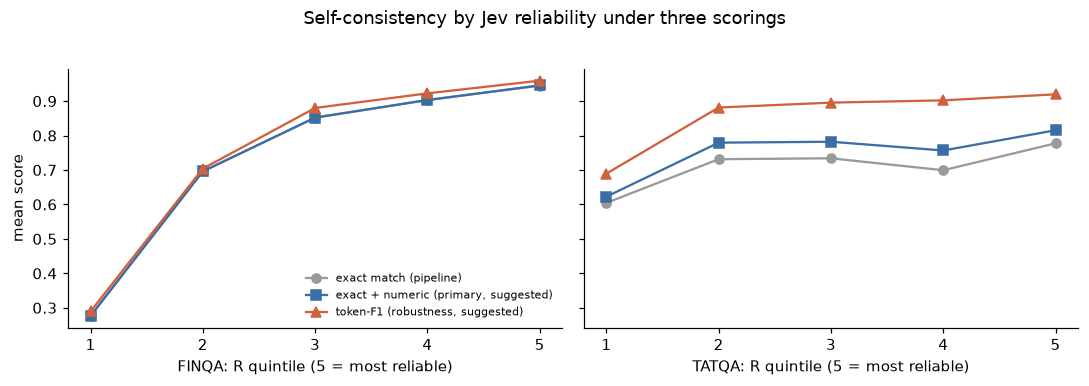

In [14]:
idef3 = pd.DataFrame({sname: {name: f"{stats.spearmanr(d3[col], d3[acc_col])[0]:.3f}"
                              for name, col in (("I (v2, primary)", "I"), ("I_v0 (sensitivity)", "I_v0"), ("I_Q3 (robustness)", "I_Q3"))}
                      for sname, (acc_col, _) in SCORERS.items()})
idef3.index.name = "ρ(I, score)"
display(idef3)
trend = pd.concat({sname: d3.groupby(["dataset", "r_quintile"])[acc_col].mean() for sname, (acc_col, _) in SCORERS.items()}, axis=1)
display(trend.round(3))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
styles = {"exact match (pipeline)": ("#9a9a9a", "o"), "exact + numeric (primary, suggested)": ("#3b6ea5", "s"),
          "token-F1 (robustness, suggested)": ("#d1603d", "^")}
for ax, ds in zip(axes, ("finqa", "tatqa")):
    for sname, (col, mk) in styles.items():
        ax.plot(trend.loc[ds].index, trend.loc[ds][sname], marker=mk, color=col, label=sname)
    ax.set_xticks([1, 2, 3, 4, 5])
    ax.set_xlabel(f"{ds.upper()}: R quintile (5 = most reliable)")
axes[0].set_ylabel("mean score")
axes[0].legend(frameon=False, fontsize=7)
fig.suptitle("Self-consistency by Jev reliability under three scorings", y=1.02)
fig.tight_layout()
fig.savefig(FIG_DIR / "sc_robustness_scorings.pdf", bbox_inches="tight")
plt.show()

**Findings of the robustness analysis.**

- **Same direction under every scoring.** R agrees with self-consistency under all three, and FinQA shows a strong, monotone rise across R quintiles every time. No conclusion depends on the scorer's direction.
- **The scorer changes the strength, and it does so where it should.** Numeric equivalence and token-F1 mainly lift **TAT-QA lookup**, the stratum whose answers are free-text spans. Agreement with R strengthens accordingly, while arithmetic items are essentially unaffected.
- **Part of TAT-QA's weakness was scoring noise.** Under token-F1, TAT-QA's trend across R quintiles becomes monotone (0.69, 0.88, 0.90, 0.90, 0.92), unlike under exact match, and ρ(R, score) rises from 0.13 to 0.20.
- **But even generous scoring leaves TAT-QA well below FinQA** (ρ 0.20 vs 0.57). The rest of the gap points to R's compression near 1 in TAT-QA.
- **Correlations are the comparable measure across scorings.** The AUROC under token-F1 (0.82 overall) is not directly comparable with the others, because "modal correct" there is defined by a different cut-off (mean token-F1 ≥ 0.5).
- **I under three definitions.** The ordering ρ(I\_v0) > ρ(I) > ρ(I\_Q3) holds under every scoring, so the v0-correctness-leak interpretation does not depend on the scorer.

**Recommendation for the paper:**
- **Primary:** report A4, and every accuracy in Specs 2 and 4, with **exact match + numeric equivalence**. It implements the protocol's "exact match with numeric tolerance" for numeric span answers.
- **Robustness:** report **token-F1**, TAT-QA's official second metric, as the robustness analysis.
- **Comparison:** show the current exact-match numbers once, to document the scorer's effect.

This remains an owner decision (blocking question 5).

## 7. Summary for the paper

In [15]:
r_em = rho_ci(df["R"], df["sc_acc"])
auc_em = auc_ci(df["modal_correct"], df["R"])
fq = df[df["dataset"] == "finqa"]; tq = df[df["dataset"] == "tatqa"]
tl = (df["dataset"] == "tatqa") & (df["answer_type"] == "lookup")
summary = pd.DataFrame([
    ["Design", "3,000 pool originals (1,500 per dataset), stratified by answer type × R quintile; 5 reason-format samples each"],
    ["Model and sampling", f"{cfg['version']} (FP8, DeepInfra via OpenRouter, pinned); T = 0.7, top-p 0.8, top-k 20, ≤ 512 tokens; seeded per sample"],
    ["Cost and time", f"{len(calls):,} calls, ${calls['cost'].sum():.2f}, about {run['wall-clock (h)']} h"],
    ["Unparsed samples", f"{smp['answer'].isna().mean():.2%} (bar 5%)"],
    ["Mean sc_acc (pipeline scoring)", f"{df['sc_acc'].mean():.3f}; TAT-QA lookup {df.loc[tl, 'sc_acc'].mean():.3f}"],
    ["Mean modal share", f"{df['sc_modal_share'].mean():.3f}"],
    ["A4: ρ(R, sc_acc)", fmt(r_em)],
    ["A4: AUROC of R → modal correct", fmt(auc_em)],
    ["Scoring sensitivity", f"TAT-QA lookup: exact {rescore.loc[('tatqa', 'lookup'), 'exact_match']:.1%} → numeric {rescore.loc[('tatqa', 'lookup'), 'plus_numeric']:.1%} → F1 ≥ 0.8 {rescore.loc[('tatqa', 'lookup'), 'plus_F1_08']:.1%}"],
    ["A4 under exact + numeric (suggested primary)", f"ρ(R, sc_acc_num) = {fmt(rho_ci(d3['R'], d3['sc_acc_num']))}"],
    ["A4 under token-F1 (suggested robustness)", f"ρ(R, sc_f1) = {fmt(rho_ci(d3['R'], d3['sc_f1']))}; FinQA {stats.spearmanr(d3.loc[d3['dataset'] == 'finqa', 'R'], d3.loc[d3['dataset'] == 'finqa', 'sc_f1'])[0]:.3f}, TAT-QA {stats.spearmanr(d3.loc[d3['dataset'] == 'tatqa', 'R'], d3.loc[d3['dataset'] == 'tatqa', 'sc_f1'])[0]:.3f}"],
], columns=["", "value"]).set_index("")
with pd.option_context("display.max_colwidth", None):
    display(summary)

text = f'''
METHODS — self-consistency comparator. As one comparator for Jev's reliability score, we measure how
consistently a strong model reproduces the gold answer. On a 3,000-item subsample of pool originals
(1,500 per dataset, stratified by answer type and by quintile of R), {cfg['version']} answered each item
five times in a brief-reasoning format (temperature 0.7, top-p 0.8, top-k 20, at most 512 tokens; fixed
per-sample seeds; one pinned FP8 deployment). sc_acc is the share of the five answers matching the gold;
the modal answer is the most frequent mutually matching answer. Answers could be extracted from
{1 - smp['answer'].isna().mean():.1%} of samples.

RESULTS — agreement with self-consistency (E0, A4). R correlates with sc_acc at ρ = {r_em[0]:.2f}
(95% CI {r_em[1]:.2f}–{r_em[2]:.2f}) and predicts whether the strong model's modal answer is correct
with AUROC {auc_em[0]:.2f} ({auc_em[1]:.2f}–{auc_em[2]:.2f}). Agreement is strong on FinQA
(ρ = {rho_ci(fq['R'], fq['sc_acc'])[0]:.2f}; AUROC {auc_ci(fq['modal_correct'], fq['R'], n=200)[0]:.2f}) and weak on TAT-QA
(ρ = {rho_ci(tq['R'], tq['sc_acc'])[0]:.2f}), where R is concentrated near 1 and span answers are hard to score. The
association is moderate overall, as expected: R judges whether a stated answer is supported by the context,
whereas sc_acc also reflects question difficulty for the strong model. Exact-match scoring understates
accuracy on free-text span answers (TAT-QA lookup: {rescore.loc[('tatqa', 'lookup'), 'exact_match']:.0%} exact,
{rescore.loc[('tatqa', 'lookup'), 'plus_numeric']:.0%} counting numerically equivalent spans, mean token-F1
{rescore.loc[('tatqa', 'lookup'), 'mean_token_F1']:.2f}). Scored as exact match with numeric equivalence, R correlates
with self-consistency at ρ = {rho_ci(d3['R'], d3['sc_acc_num'])[0]:.2f}; with token-F1 as a robustness analysis,
at ρ = {rho_ci(d3['R'], d3['sc_f1'])[0]:.2f}. The direction and the dataset pattern are the same under every scoring.
'''
print(text)

,value
,
Design,"3,000 pool originals (1,500 per dataset), stratified by answer type × R quintile; 5 reason-format samples each"
Model and sampling,"Qwen/Qwen3-235B-A22B-Instruct-2507 (FP8, DeepInfra via OpenRouter, pinned); T = 0.7, top-p 0.8, top-k 20, ≤ 512 tokens; seeded per sample"
Cost and time,"15,000 calls, $2.23, about 5.19 h"
Unparsed samples,0.46% (bar 5%)
Mean sc_acc (pipeline scoring),0.722; TAT-QA lookup 0.587
Mean modal share,0.922
"A4: ρ(R, sc_acc)","0.301 [0.268, 0.333]"
A4: AUROC of R → modal correct,"0.676 [0.653, 0.699]"
Scoring sensitivity,TAT-QA lookup: exact 58.7% → numeric 66.1% → F1 ≥ 0.8 74.3%



METHODS — self-consistency comparator. As one comparator for Jev's reliability score, we measure how
consistently a strong model reproduces the gold answer. On a 3,000-item subsample of pool originals
(1,500 per dataset, stratified by answer type and by quintile of R), Qwen/Qwen3-235B-A22B-Instruct-2507 answered each item
five times in a brief-reasoning format (temperature 0.7, top-p 0.8, top-k 20, at most 512 tokens; fixed
per-sample seeds; one pinned FP8 deployment). sc_acc is the share of the five answers matching the gold;
the modal answer is the most frequent mutually matching answer. Answers could be extracted from
99.5% of samples.

RESULTS — agreement with self-consistency (E0, A4). R correlates with sc_acc at ρ = 0.30
(95% CI 0.27–0.33) and predicts whether the strong model's modal answer is correct
with AUROC 0.68 (0.65–0.70). Agreement is strong on FinQA
(ρ = 0.55; AUROC 0.84) and weak on TAT-QA
(ρ = 0.13), where R is concentrated near 1 and span answers are hard to score. 

## 8. Limitations and notes for later

1. **Scoring decision pending (blocking question 5).** §6b reports the suggested set-up: exact match + numeric equivalence as primary, token-F1 as robustness, the current exact match for comparison. Both alternatives are computed here, in the notebook, from the cached samples; the pipeline's `sc_acc` column still uses exact match. Once the owner decides, the scorer should be implemented once in the pipeline (shared by Specs 2–4) and `sc_acc` re-scored from the cached samples, at no API cost, before Spec 3's formal A4.
2. **The same decision applies to Spec 2 (`acc`) and Spec 4 (proxy C).** Settle it before the GPU runs, so that every accuracy in the study uses one scorer.
3. **Possible coupling between Qwen and Jev.** If Jev is built on a Qwen model (an open question for TypeSafe), agreement between R and Qwen's self-consistency could partly reflect shared training rather than shared signal about the data.
4. **FP8 serving.** The strong model runs in FP8 at the provider. Sampling is seeded, but reproducibility across provider updates is not guaranteed. The full responses are archived (DVC) so the analysis can be re-run without new calls.
5. **Subsample only.** `sc_acc` exists for 3,000 of 19,269 originals by design (Spec 3). It is a comparator for E0, not a covariate in the hypothesis tests.
6. **I under three definitions.** As for every I-based result, the correlations of I with `sc_acc` are reported under the primary I (v2), I\_v0 and I\_Q3 (§5). Spec 3's formal A2 and A4 should repeat this.

## 9. Relation to Thread 2: consistency–accuracy dissociation

**Reference.** Zhang, Gondara & Novikova (2026), *When Judges Agree and Are Wrong: Consistency-Accuracy Dissociation as a Blind Spot for Label-Free Evaluation*, arXiv:2610.21128.

The paper studies the joint distribution of consistency and accuracy at the example level, on financial QA (CFA L1/L2, CMT, FinQA; GPT-5.5 and Claude Opus 4.5; ten consistency dimensions). It divides examples into four quadrants:

- **Q1:** high consistency, correct;
- **Q2:** low consistency, correct;
- **Q3:** low consistency, incorrect;
- **Q4, CBI (consistent but inaccurate):** high consistency, incorrect. This quadrant is invisible to any agreement-based signal.

**Headline findings:**
- At t = 0.8, 60% of all errors are CBI.
- 77.7% of CBI cases show answer collapse: the identical wrong answer every time.
- CBI is nearly threshold-invariant, shared across model families, and higher for free-form FinQA (7.49%).

**Recommendations:**
- estimate the Q4 mass on a small labelled sample;
- disclose the certified-set error rate, the CBI-within-inaccurate rate and the answer-collapse rate.

**How this run maps onto the paper.** One of its ten dimensions, *self-consistency* (repeated sampling), is exactly what this run measures, with verified gold labels and FinQA in common. Consistency is computed as the paper defines it, 1 − H/log n over the 5 answers, with unparsed answers never agreeing.

**Caveat on the threshold.** With n = 5, a 4–1 split scores 0.69. So **t = 0.8 means unanimity**: answer collapse among CBI is 100% by construction, and the threshold curve is flat from 0.7 to 1.0. Spec 4's CBI definition ("modal share ≥ 0.8", i.e. at least 4 of 5) is a looser variant; both are reported below.

**What this section adds to the paper's question.** Jev's R is a *label-aware* judgment that involves no agreement. Inside the unanimous stratum, where agreement-based signals are blind by construction, can R, or the thesis's determinacy and consequence scores, tell reliable answers (Q1) from CBI?

In [16]:
def norm_ans(a):
    return re.sub(r"\s+", " ", a.strip().lower())


def entropy_consistency(answers):
    labels = [norm_ans(a) if a is not None else f"__unparsed_{i}" for i, a in enumerate(answers)]
    p = np.array(list(Counter(labels).values()), float) / len(labels)
    return float(1 - (-(p * np.log(p)).sum()) / np.log(len(labels)))

grp = s2.sort_values(["item_id", "k"]).groupby("item_id")
cons = pd.DataFrame({
    "consistency": grp["answer"].apply(lambda a: entropy_consistency(list(a))),
    "unanimous": grp["answer"].apply(lambda a: bool(a.notna().all() and a.map(norm_ans).nunique() == 1)),
    "modal4": grp["answer"].apply(lambda a: (a.dropna().map(norm_ans).value_counts().max() if a.notna().any() else 0) >= 4),
})
t9 = d3.join(cons, on="item_id").join(items[["source_answer_type"]].rename(columns={"source_answer_type": "op"}), on="item_id")
WRONG = {"exact match (pipeline)": ~t9["modal_correct"],
         "exact + numeric (primary, suggested)": t9["sc_acc_num"] < 0.6,
         "lenient: + token-F1 ≥ 0.8": t9["item_id"].map(item_rs["sc_acc_f1"]) < 0.6}


def quadrants(high, wrong):
    n, W = len(high), int(wrong.sum())
    cbi = high & wrong
    return {"Q1 high/correct %": (high & ~wrong).mean() * 100, "Q2 low/correct %": (~high & ~wrong).mean() * 100,
            "Q3 low/incorrect %": (~high & wrong).mean() * 100, "Q4 CBI %": cbi.mean() * 100,
            "CBI within incorrect %": cbi.sum() / max(W, 1) * 100,
            "certified-set error %": wrong[high].mean() * 100 if high.any() else np.nan,
            "certified share %": high.mean() * 100}

rows = []
for sname, wrong in WRONG.items():
    rows.append({"scoring": sname, "consistency def.": "entropy ≥ 0.8 (paper; = unanimous at n = 5)", **quadrants(t9["consistency"] >= 0.8, wrong)})
    rows.append({"scoring": sname, "consistency def.": "modal share ≥ 0.8 (Spec 4; ≥ 4 of 5)", **quadrants(t9["modal4"], wrong)})
quad = pd.DataFrame(rows).set_index(["scoring", "consistency def."])
display(quad.round(1))
print("Paper (all datasets, t = 0.8): Q4 5.24% of observations; CBI within incorrect 60.2%; FinQA CBI 7.49%; answer collapse 77.7%.")
print(f"Answer collapse among CBI here (paper's definition, exact match): "
      f"{t9.loc[(t9['consistency'] >= 0.8) & WRONG['exact match (pipeline)'], 'unanimous'].mean():.0%} (by construction at n = 5)")

Q1 high/correct %  \
scoring                              consistency def.                                                 
exact match (pipeline)               entropy ≥ 0.8 (paper; = unanimous at n = 5)               47.4   
                                     modal share ≥ 0.8 (Spec 4; ≥ 4 of 5)                      59.1   
exact + numeric (primary, suggested) entropy ≥ 0.8 (paper; = unanimous at n = 5)               48.3   
                                     modal share ≥ 0.8 (Spec 4; ≥ 4 of 5)                      60.5   
lenient: + token-F1 ≥ 0.8            entropy ≥ 0.8 (paper; = unanimous at n = 5)               49.5   
                                     modal share ≥ 0.8 (Spec 4; ≥ 4 of 5)                      62.5   

                                                                                  Q2 low/correct %  \
scoring                              consistency def.                                                
exact match (pipeline)               entropy ≥ 0.8 (paper; = unanimous at n = 5)              25.4   
                                     modal share ≥ 0.8 (Spec 4; ≥ 4 of 5)                     13.7   
exact + numeric (primary, suggested) entropy ≥ 0.8 (paper; = unanimous at n = 5)              26.4   
                                     modal share ≥ 0.8 (Spec 4; ≥ 4 of 5)                     14.1   
lenient: + token-F1 ≥ 0.8            entropy ≥ 0.8 (paper; = unanimous at n = 5)              28.6   
                                     modal share ≥ 0.8 (Spec 4; ≥ 4 of 5)                     15.6   

                                                                                  Q3 low/incorrect %  \
scoring                              consistency def.                                                  
exact match (pipeline)               entropy ≥ 0.8 (paper; = unanimous at n = 5)                16.9   
                                     modal share ≥ 0.8 (Spec 4; ≥ 4 of 5)                       12.0   
exact + numeric (primary, suggested) entropy ≥ 0.8 (paper; = unanimous at n = 5)                16.0   
                                     modal share ≥ 0.8 (Spec 4; ≥ 4 of 5)                       11.5   
lenient: + token-F1 ≥ 0.8            entropy ≥ 0.8 (paper; = unanimous at n = 5)                13.7   
                                     modal share ≥ 0.8 (Spec 4; ≥ 4 of 5)                       10.0   

                                                                                  Q4 CBI %  \
scoring                              consistency def.                                        
exact match (pipeline)               entropy ≥ 0.8 (paper; = unanimous at n = 5)      10.3   
                                     modal share ≥ 0.8 (Spec 4; ≥ 4 of 5)             15.2   
exact + numeric (primary, suggested) entropy ≥ 0.8 (paper; = unanimous at n = 5)       9.4   
                                     modal share ≥ 0.8 (Spec 4; ≥ 4 of 5)             13.8   
lenient: + token-F1 ≥ 0.8            entropy ≥ 0.8 (paper; = unanimous at n = 5)       8.2   
                                     modal share ≥ 0.8 (Spec 4; ≥ 4 of 5)             11.8   

                                                                                  CBI within incorrect %  \
scoring                              consistency def.                                                      
exact match (pipeline)               entropy ≥ 0.8 (paper; = unanimous at n = 5)                    37.7   
                                     modal share ≥ 0.8 (Spec 4; ≥ 4 of 5)                           56.0   
exact + numeric (primary, suggested) entropy ≥ 0.8 (paper; = unanimous at n = 5)                    37.0   
                                     modal share ≥ 0.8 (Spec 4; ≥ 4 of 5)                           54.6   
lenient: + token-F1 ≥ 0.8            entropy ≥ 0.8 (paper; = unanimous at n = 5)                    37.3   
                                     modal share ≥ 0.8 (Spec 4; ≥ 4 of 5)                         

Paper (all datasets, t = 0.8): Q4 5.24% of observations; CBI within incorrect 60.2%; FinQA CBI 7.49%; answer collapse 77.7%.
Answer collapse among CBI here (paper's definition, exact match): 100% (by construction at n = 5)


In [17]:
high = t9["consistency"] >= 0.8
strat = []
for sname in ("exact match (pipeline)", "exact + numeric (primary, suggested)"):
    w = WRONG[sname]
    for keys, g in t9.groupby(["dataset", "answer_type"]):
        idx = g.index
        strat.append({"scoring": sname, "dataset": keys[0], "answer_type": keys[1], "n": len(g),
                      "CBI %": (high[idx] & w[idx]).mean() * 100,
                      "CBI within incorrect %": (high[idx] & w[idx]).sum() / max(int(w[idx].sum()), 1) * 100,
                      "certified-set error %": w[idx][high[idx]].mean() * 100})
display(pd.DataFrame(strat).set_index(["scoring", "dataset", "answer_type"]).round(1))
ops = t9.assign(cbi=high & WRONG["exact + numeric (primary, suggested)"]).groupby(["dataset", "op"])["cbi"].agg(["mean", "size"])
display((ops.assign(mean=ops["mean"] * 100).rename(columns={"mean": "CBI %", "size": "n"})).round(1))
sweep = pd.DataFrame({sname: {t: ((t9["consistency"] >= t) & w).mean() * 100 for t in (0.5, 0.6, 0.7, 0.8, 0.9, 1.0)}
                      for sname, w in WRONG.items()})
sweep.index.name = "threshold t"
display(sweep.round(1))

n  CBI %  \
scoring                              dataset answer_type                
exact match (pipeline)               finqa   arith        1456   10.6   
                                             lookup         44    2.3   
                                     tatqa   arith         663    5.0   
                                             lookup        837   14.2   
exact + numeric (primary, suggested) finqa   arith        1456   10.6   
                                             lookup         44    2.3   
                                     tatqa   arith         663    5.0   
                                             lookup        837   11.0   

                                                          CBI within incorrect %  \
scoring                              dataset answer_type                           
exact match (pipeline)               finqa   arith                          40.6   
                                             lookup                         33.3   
                                     tatqa   arith                          38.4   
                                             lookup                         34.5   
exact + numeric (primary, suggested) finqa   arith                          40.4   
                                             lookup                         33.3   
                                     tatqa   arith                          37.9   
                                             lookup                         32.2   

                                                          certified-set error %  
scoring                              dataset answer_type                         
exact match (pipeline)               finqa   arith                         19.0  
                                             lookup                         3.4  
                                     tatqa   arith                          8.8  
                                             lookup                        23.3  
exact + numeric (primary, suggested) finqa   arith                         19.0  
                                             lookup                         3.4  
                                     tatqa   arith                          8.8  
                                             lookup                        18.0

CBI %    n
dataset op                       
finqa   add             16.8  113
        divide           9.2  979
        greater          2.6   38
        multiply        12.9   70
        subtract        14.1  256
        table_average    0.0   25
        table_max       10.0   10
        table_min        0.0    5
        table_sum        0.0    4
tatqa   arithmetic       4.8  627
        count            8.3   36
        multi-span       9.8  214
        span            11.4  623

,exact match (pipeline),"exact + numeric (primary, suggested)",lenient: + token-F1 ≥ 0.8
threshold t,,,
0.5,18.5,17.0,14.2
0.6,15.2,13.8,11.8
0.7,10.3,9.4,8.2
0.8,10.3,9.4,8.2
0.9,10.3,9.4,8.2
1.0,10.3,9.4,8.2


**Findings: quadrants and disclosure fields (analysis 1).**
- **Under the paper's definition** (t = 0.8, which is unanimity at n = 5) and the suggested primary scoring:
  - **CBI mass:** 9.4% of items, which is 37% of Qwen's errors.
  - **Certified-set error:** 16.2% of the items self-consistency would certify are wrong.
  - **Comparison:** the paper reports 5.24% of observations across its datasets, and 7.49% for FinQA.
- **Under Spec 4's looser definition (at least 4 of 5 samples agree),** CBI within incorrect rises to **about 55%, close to the paper's 60%**. With fewer than five agreeing samples allowed, more errors count as "consistent".
- **The scoring matters for the measurement itself.** Counting numeric equivalence or near-verbatim spans lowers CBI from 10.3% (exact match) to 9.4% and 8.2%, almost entirely in TAT-QA lookup (14.2% → 11.0% with numeric equivalence). Those removed cases are scoring artefacts: a model consistently giving a correct but differently formatted answer looks consistently wrong. **For Thread 2 this is a methodological point:** CBI rates on free-form answers depend on the answer matcher, so the matcher should be reported with them.
- **Where CBI sits.** It is highest for FinQA programs ending in add, subtract or multiply (13–17%) and for TAT-QA text spans (10–11%). It is lowest for table operations and TAT-QA arithmetic (about 5%). The free-text contrast echoes the paper's finding that free-form formats carry more CBI.
- **Threshold.** The sweep is flat from t = 0.7 upward. That's a property of n = 5 (the only values above 0.69 are unanimity), not evidence for or against threshold invariance.

In [18]:
w = WRONG["exact + numeric (primary, suggested)"]
una = t9[high].copy()
una["cbi"] = w[high]
SIGNALS = {"R (Q1, support)": "R", "R′ (paraphrase)": "R_para", "Q2 determinacy (v2, answer-free)": None,
           "Q3 consequence": "I_Q3", "I (v2, primary)": "I", "I_v0 (sensitivity)": "I_v0"}
q2v2 = j2["q2"]
una["q2_v2"] = una["item_id"].map(q2v2)
SIGNALS["Q2 determinacy (v2, answer-free)"] = "q2_v2"
rows = []
for name, col in SIGNALS.items():
    for label, g in (("all", una), ("FinQA", una[una["dataset"] == "finqa"]), ("TAT-QA", una[una["dataset"] == "tatqa"])):
        a = auc_ci(~g["cbi"], g[col], n=1000)
        rows.append({"signal": name, "subset": label, "n unanimous": len(g), "n CBI": int(g["cbi"].sum()),
                     "median, Q1 quadrant": g.loc[~g["cbi"], col].median(), "median, CBI": g.loc[g["cbi"], col].median(),
                     "AUROC (Q1 vs CBI)": fmt(a)})
judge = pd.DataFrame(rows).set_index(["signal", "subset"])
with pd.option_context("display.max_colwidth", None):
    display(judge.round(3))
print("Inside the unanimous stratum, any agreement-based signal has AUROC 0.5 by construction (every item is maximally consistent).")

n unanimous  n CBI  \
signal                           subset                       
R (Q1, support)                  all            1730    281   
                                 FinQA           844    156   
                                 TAT-QA          886    125   
R′ (paraphrase)                  all            1730    281   
                                 FinQA           844    156   
                                 TAT-QA          886    125   
Q2 determinacy (v2, answer-free) all            1730    281   
                                 FinQA           844    156   
                                 TAT-QA          886    125   
Q3 consequence                   all            1730    281   
                                 FinQA           844    156   
                                 TAT-QA          886    125   
I (v2, primary)                  all            1730    281   
                                 FinQA           844    156   
                                 TAT-QA          886    125   
I_v0 (sensitivity)               all            1730    281   
                                 FinQA           844    156   
                                 TAT-QA          886    125   

                                         median, Q1 quadrant  median, CBI  \
signal                           subset                                     
R (Q1, support)                  all                   0.980        0.800   
                                 FinQA                 0.970        0.430   
                                 TAT-QA                0.980        0.970   
R′ (paraphrase)                  all                   0.970        0.780   
                                 FinQA                 0.950        0.450   
                                 TAT-QA                0.980        0.980   
Q2 determinacy (v2, answer-free) all                   0.870        0.810   
                                 FinQA                 0.820        0.760   
                                 TAT-QA                0.920        0.870   
Q3 consequence                   all                   0.970        0.930   
                                 FinQA                 0.970        0.935   
                                 TAT-QA                0.970        0.910   
I (v2, primary)                  all                   0.900        0.830   
                                 FinQA                 0.862        0.800   
                                 TAT-QA                0.930        0.870   
I_v0 (sensitivity)               all                   0.925        0.775   
                                 FinQA                 0.895        0.680   
                                 TAT-QA                0.955        0.875   

                                            AUROC (Q1 vs CBI)  
signal                           subset                        
R (Q1, support)                  all     0.749 [0.713, 0.785]  
                                 FinQA   0.858 [0.820, 0.892]  
                                 TAT-QA  0.629 [0.565, 0.687]  
R′ (paraphrase)                  all     0.739 [0.700, 0.776]  
                                 FinQA   0.863 [0.824, 0.895]  
                                 TAT-QA  0.622 [0.560, 0.680]  
Q2 determinacy (v2, answer-free) all     0.632 [0.595, 0.668]  
                                 FinQA   0.599 [0.550, 0.650]  
                                 TAT-QA  0.651 [0.596, 0.706]  
Q3 consequence                   all     0.641 [0.606, 0.674]  
                                 FinQA   0.643 [0.600, 0.684]  
                                 TAT-QA  0.647 [0.594, 0.694]  
I (v2, primary)                  all     0.656 [0.623, 0.690]  
                                 FinQA   0.620 [0.574, 0.666]  
                                 TAT-QA  0.676 [0.622, 0.726]  
I_v0 (sensitivity)               all     0.746 [0.712, 0.779]  
                                 FinQA   0.804 [0.765, 0.840]  
                       

Inside the unanimous stratum, any agreement-based signal has AUROC 0.5 by construction (every item is maximally consistent).


In [19]:
import statsmodels.formula.api as smf

una["finqa"] = (una["dataset"] == "finqa").astype(int)
una["lookup"] = (una["answer_type"] == "lookup").astype(int)
una["log_tokens"] = np.log(una["qa_tokens"])
una["cbi_i"] = una["cbi"].astype(int)
z = lambda c: (una[c] - una[c].mean()) / una[c].std()
for c in ("R", "q2_v2", "I_Q3", "log_tokens"):
    una[f"z_{c}"] = z(c)
fit = smf.logit("cbi_i ~ z_R + z_q2_v2 + z_I_Q3 + z_log_tokens + finqa + lookup", data=una).fit(disp=False)
coef = pd.DataFrame({"odds ratio per SD": np.exp(fit.params), "CI low": np.exp(fit.conf_int()[0]),
                     "CI high": np.exp(fit.conf_int()[1]), "p": fit.pvalues}).drop(index="Intercept")
display(coef.round(3))
print(f"Logit of CBI (vs Q1) among unanimous items, n = {int(fit.nobs)}; pseudo-R² = {fit.prsquared:.3f}. "
      "Predictors standardised; finqa and lookup are indicators.")

,odds ratio per SD,CI low,CI high,p
z_R,0.329,0.282,0.383,0.000
z_q2_v2,0.873,0.751,1.014,0.075
z_I_Q3,0.951,0.814,1.111,0.526
z_log_tokens,0.939,0.777,1.135,0.518
finqa,1.344,0.837,2.158,0.221
lookup,3.694,2.396,5.694,0.000


Logit of CBI (vs Q1) among unanimous items, n = 1730; pseudo-R² = 0.242. Predictors standardised; finqa and lookup are indicators.


**Findings: a label-aware judge inside the blind spot (analyses 2 and 3).**
- **Jev's R recovers part of the CBI quadrant.** Every unanimous item is maximally consistent, so agreement-based signals have AUROC 0.5 there by construction.
  - **R** separates reliable items (Q1) from CBI with **AUROC 0.75 [0.71, 0.79]**, and the paraphrased R′ agrees (0.74).
  - **FinQA** is the strongest case: AUROC 0.86, with median R 0.97 for reliable items against **0.43** for CBI.
  - **TAT-QA** is weaker (0.63), where R is concentrated near 1.
- **The thesis's I behaves as its definition predicts.**
  - **Primary I and its parts:** I (v2) separates Q1 from CBI only modestly (0.66), and so do its parts, determinacy Q2 (0.63) and consequence Q3 (0.64).
  - **v0's I:** it separates almost as well as R (**0.75**). That is consistent with v0's determinacy question carrying correctness information, the leak battery v2 removed.
- **In a joint logistic model,** R is the dominant predictor (odds ratio 0.33 per SD), and **lookup items are 3.7 times as likely to be CBI**. Determinacy is marginal (p = 0.075), and consequence and item length add nothing once R is in the model.
- **What this means and does not mean.** R judges the *gold* answer, not Qwen's answer. Low R on CBI items says the gold answer looks *less supported by the context*. That fits two readings, which the data cannot yet separate:
  - **(a)** Qwen is confidently wrong on items that are genuinely hard to support from the text;
  - **(b)** part of the CBI mass reflects weak or ambiguous gold labels or questions, so the "error" lies partly on the dataset side.

  Reading (b) is the thesis's reliability construct showing up in Thread 2's quadrant. **§10 tests this directly** by asking Jev about Qwen's own answer. Jev sides with Qwen against the gold on a third of CBI items, which supports reading (b) for part of the mass. The hand audit (§9.1) remains the decisive check.

In [20]:
pool_orig = orig.join(j2[["V", "I"]].rename(columns={"V": "V_v2", "I": "I_v2"}))
pool_orig["V_v2"] = pool_orig["V_v2"]
sel = []
for ds, g in t9.groupby("dataset"):
    k = int(round(0.2 * len(g)))
    sets = {"top-20% R": set(g.nlargest(k, "R")["item_id"]),
            "top-20% V (R × I)": set(g.assign(V=g["R"] * g["I"]).nlargest(k, "V")["item_id"]),
            "top-20% I": set(g.nlargest(k, "I")["item_id"]),
            "self-consistency filter (unanimous)": set(g.loc[g["consistency"] >= 0.8, "item_id"])}
    cbi_ids = set(g.loc[(g["consistency"] >= 0.8) & WRONG["exact + numeric (primary, suggested)"][g.index], "item_id"])
    wrong_ids = set(g.loc[WRONG["exact + numeric (primary, suggested)"][g.index], "item_id"])
    for name, ids in sets.items():
        sel.append({"dataset": ds, "selection": name, "size": len(ids),
                    "share of items Qwen gets wrong %": len(ids & wrong_ids) / len(ids) * 100,
                    "CBI items retained %": len(ids & cbi_ids) / max(len(cbi_ids), 1) * 100,
                    "overlap with self-consistency filter %": len(ids & sets["self-consistency filter (unanimous)"]) / len(ids) * 100})
display(pd.DataFrame(sel).set_index(["dataset", "selection"]).round(1))
print("Within the 3,000-item subsample, per dataset; 'wrong' and CBI under exact + numeric scoring.")

size  \
dataset selection                                   
finqa   top-20% R                             300   
        top-20% V (R × I)                     300   
        top-20% I                             300   
        self-consistency filter (unanimous)   844   
tatqa   top-20% R                             300   
        top-20% V (R × I)                     300   
        top-20% I                             300   
        self-consistency filter (unanimous)   886   

                                             share of items Qwen gets wrong %  \
dataset selection                                                               
finqa   top-20% R                                                         5.7   
        top-20% V (R × I)                                                 6.7   
        top-20% I                                                        11.7   
        self-consistency filter (unanimous)                              18.5   
tatqa   top-20% R                                                        21.7   
        top-20% V (R × I)                                                12.0   
        top-20% I                                                        13.7   
        self-consistency filter (unanimous)                              14.1   

                                             CBI items retained %  \
dataset selection                                                   
finqa   top-20% R                                             6.4   
        top-20% V (R × I)                                     4.5   
        top-20% I                                            12.2   
        self-consistency filter (unanimous)                 100.0   
tatqa   top-20% R                                            17.6   
        top-20% V (R × I)                                    10.4   
        top-20% I                                            12.8   
        self-consistency filter (unanimous)                 100.0   

                                             overlap with self-consistency filter %  
dataset selection                                                                    
finqa   top-20% R                                                              70.3  
        top-20% V (R × I)                                                      62.0  
        top-20% I                                                              62.7  
        self-consistency filter (unanimous)                                   100.0  
tatqa   top-20% R                                                              61.7  
        top-20% V (R × I)                                                      74.3  
        top-20% I                                                              75.0  
        self-consistency filter (unanimous)                                   100.0

Within the 3,000-item subsample, per dataset; 'wrong' and CBI under exact + numeric scoring.


**Findings: label-free versus Jev-based data selection (the "now" part of analysis 5).**
- **What the self-consistency filter does.** The filter, the label-free data-quality filter the paper warns about, keeps the 56–59% of items Qwen answers unanimously. It retains **every CBI item by definition**: 18.5% of its FinQA items and 14.1% of its TAT-QA items are ones Qwen gets wrong.
- **FinQA: Jev's reliability gate screens CBI out.** Top-20% R keeps only 5.7% items Qwen gets wrong, and 6.4% of all CBI items, against the 20% a random 20% selection would keep in expectation.
- **TAT-QA: R alone doesn't help.** Top-20% R keeps *more* wrong items (21.7%) than the self-consistency filter and retains CBI at about the random rate (17.6%), because TAT-QA's R is squeezed near 1. Top-20% V (R × I) works best there (12.0% wrong; 10.4% of CBI retained).
- **For the thesis:** where R is discriminative, *certainty in the sense of agreement* certifies confidently disputed items that Jev's reliability gate screens out. Where R is compressed, combining it with I (V) is what helps.
- **Open question:** whether the screened-out items are harmful or merely surprising is for proxy G (H4, H5; §9.1). These are descriptive comparisons on the subsample, not selection conditions of the pre-registered E1-C.

### 9.1 Follow-up analyses: status

1. **Jev on Qwen's own answers (analysis 2, clean version). Done, see §10.**
   - **What was run:** pre-specified in the plan on 25 October 2026, 19:48 UTC. 2,996 requests, about $0.03. For every item with a modal answer, Jev answered Q1 and Q1′ with **Qwen's modal answer** as the stated answer.
   - **Result:** inside the unanimous stratum, Jev's judgment of Qwen's answer separates correct answers from CBI with only **AUROC 0.62** (FinQA 0.59, TAT-QA 0.65). That is much weaker than Jev's judgment of the gold on the same items (0.75; FinQA 0.86). Two thirds of confident errors get P(supported) ≥ 0.9.
   - **Joint pattern within the 281 CBI items:** Jev supports both the gold and Qwen's answer in 163 items, **only Qwen's answer in 90**, only the gold in 14, and neither in 14.
   - **Conclusion:** an agreement-free judge does not close the CBI blind spot when it judges the model's output. Judging the gold label is where Jev is informative.
2. **Hand audit of CBI items (analysis 3; annotators). Still to do, now with a sharper sampling plan.**
   - **Labels:** about 100 CBI items under the primary scoring, each labelled *model error*, *scoring artefact*, *ambiguous or under-determined question*, or *questionable gold label*, through the CSV annotation workflow.
   - **Sampling, stratified by §10's joint pattern rather than only by dataset × answer type:**
     - **oversample the 90 items where Jev sides with Qwen against the gold.** They are mostly FinQA arithmetic, and the first examples look like ambiguous questions or suspect gold values;
     - include items where Jev supports both answers (163), and the few where it catches Qwen's error (14).
   - **Purpose:** the audit is the paper's recommended "Q4 mass on a small labelled sample". It decides how much of the CBI mass is model error and how much is item ambiguity or label noise, which §9 and §10 cannot separate on their own.
3. **A judge from a different model family (new).** If Jev is built on Qwen (still unanswered by TypeSafe), generator–judge convergence in §10 could partly reflect shared training. Repeating §10 with a judge from another family separates the two explanations; the judge-comparison work being done in another session could provide one.
4. **Cross-model convergence between generators (analysis 4; after Spec 2).**
   - **What:** compare Qwen's CBI items with OLMo 3's, from Spec 2's 5 `reason` samples per item, and count shared CBI items against the independence expectation; the paper found 3.54× across GPT and Claude.
   - **Why:** together with §10's generator–judge convergence, this would show whether confident errors are shared across a 235B generator, a 7B generator and an independent judge.
5. **Value of confidently disputed items (analysis 5; after proxy G; exploratory, to pre-register before G is computed).**
   - **What:** compare G for CBI items, Q1 items and items screened out by top-R.
   - **Split by §10's pattern:** keep "Jev sides with Qwen" items separate from the rest, since some of them may have questionable gold labels.
   - **Why:** this is the H4/H5 link and the protocol's open decision on framing "H5 and the CBI link as a Thread 2 bridge".
6. **Align the CBI definition before the GPU runs (analysis 6; owner decision).**
   - **The mismatch:** Spec 4's CBI rate for proxy C counts an answer as consistent when the modal share is ≥ 0.8, i.e. at least 4 of 5 samples. The paper's entropy measure at t = 0.8 means 5 of 5.
   - **Proposal:** pick one before Spec 4 runs, so the paper can cite Thread 2's definition exactly, and report the other as a sensitivity analysis. Both are tabulated in §9 above.

## 10. Can an agreement-free judge catch confident errors? Jev judging Qwen's own answers

### 10.1 Motivation

Thread 2's central finding is that most errors of strong models are **consistent but inaccurate (CBI)**: the model gives the same wrong answer every time. So any signal built on agreement (self-consistency, majority vote, cross-model agreement) certifies them as reliable. The paper ends with the obvious next question: **is there a label-free signal that is not based on agreement and can see into this blind spot?**

§9 gave a first, indirect answer: inside the unanimous stratum, Jev's R separates reliable items from CBI with AUROC 0.75. But **R is Jev's judgment of the *gold* answer**, not of the model's answer. A low R on a CBI item says "the gold answer looks weakly supported". That is equally consistent with:

- **(a)** the model being confidently wrong on a hard item;
- **(b)** the item itself being the problem: a weak or ambiguous gold label, or an under-determined question.

The direct test is to show Jev **the model's own answer** and ask the same support question. That is what a label-free deployment would do: there is no gold, only the model's output and a judge.

### 10.2 Why it matters

- **For Thread 2:** it is the natural follow-up experiment. A high AUROC would mean a calibrated external judge recovers part of the CBI mass that agreement-based filters leave in the certified set. An AUROC near 0.5 would mean the confident errors also look plausible to an independent judge, strengthening the paper's "irreducible residual" conclusion.
- **For this paper (implication-weighted selection):**
  - It clarifies *what* Jev's reliability score measures. R is meant to be P(datum is true), a property of a training example's label.
  - If Jev is good at judging gold labels but poor at catching a model's confident errors, R's validity is about data, which is exactly the role the thesis gives it as a data-selection gate. It also bounds what Jev could do as a general error detector.
- **For the span-scoring decision (blocking question 5):** Jev judges meaning, not strings. Its verdicts on answers that exact match rejects but numeric or F1 matching accepts give independent evidence on whether those are genuine errors.

### 10.3 Design (pre-specified before any score was seen)

The design was recorded in the implementation plan on 25 October 2026 at 19:48 UTC, before any of these Jev scores existed.

- **Items:** all 2,996 subsample items with a modal answer; 4 items had no extractable answer in any sample.
- **Request:** one batched request per item. The state is the `judge` rendering of the item with **Qwen's modal answer as the stated answer**. The questions are Q1 and Q1′ (support), verbatim from the frozen battery and identical in v0, v1 and v2. The run uses Spec 1's client, cache and pinned model (`jev-1.14.0`), with single scoring.
- **Primary metric:** within the unanimous stratum, the AUROC of Jev's P(yes | Q1) on Qwen's answer for separating correct answers from CBI, under the suggested primary scoring (exact match + numeric equivalence).
- **Secondary metrics:**
  - the same AUROC under other scorings, for Q1′, and on all items;
  - Jev's scores on likely scoring artefacts;
  - the joint pattern of Jev's verdicts on the gold and on Qwen's answer within CBI.
- **Cost:** 2,996 requests, 3.3M input tokens, about $0.03. Script: `code/scripts/jev_on_qwen_answers.py`; outputs in the snapshot named above.

In [21]:
jq = pd.read_parquet(JQ_DIR / "jev_on_qwen.parquet").set_index("item_id")
jman = json.loads((JQ_DIR / "manifest.json").read_text())
print({k: jman[k] for k in ("jev_model", "items", "requests_sent", "input_tokens")}, "| questions:", jman["questions"])
t10 = t9.set_index("item_id").join(jq[["p_q1", "p_q1p", "stated_answer"]])
t10 = t10[t10["p_q1"].notna()]
t10["wrong_em"] = WRONG["exact match (pipeline)"].reindex(t9.index).to_numpy()[t9["item_id"].isin(t10.index).to_numpy()]
t10["wrong_num"] = t10["sc_acc_num"] < 0.6
t10["wrong_f1"] = t10.index.map(item_rs["sc_acc_f1"]) < 0.6
u10 = t10[t10["consistency"] >= 0.8]
print(f"scored items {len(t10):,}; unanimous {len(u10):,}; CBI under the primary scoring {int(u10['wrong_num'].sum())}")


def auc_row(frame, wrong_col, score):
    a = auc_ci(~frame[wrong_col], frame[score], n=1000)
    return fmt(a)

rows = []
for label, g in (("all", u10), ("FinQA", u10[u10["dataset"] == "finqa"]), ("TAT-QA", u10[u10["dataset"] == "tatqa"]),
                 ("arith", u10[u10["answer_type"] == "arith"]), ("lookup", u10[u10["answer_type"] == "lookup"])):
    rows.append({"subset": label, "n unanimous": len(g), "n CBI": int(g["wrong_num"].sum()),
                 "Jev on Qwen's answer (Q1) — PRIMARY": auc_row(g, "wrong_num", "p_q1"),
                 "Jev on Qwen's answer (Q1′)": auc_row(g, "wrong_num", "p_q1p"),
                 "Jev on the gold answer (R, §9)": auc_row(g, "wrong_num", "R")})
prim = pd.DataFrame(rows).set_index("subset")
with pd.option_context("display.max_colwidth", None):
    display(prim)
sec = pd.Series({"exact-match scoring": auc_row(u10, "wrong_em", "p_q1"),
                 "exact + numeric (primary)": auc_row(u10, "wrong_num", "p_q1"),
                 "token-F1 ≥ 0.8 scoring": auc_row(u10, "wrong_f1", "p_q1"),
                 "all items, not only unanimous (primary scoring)": auc_row(t10, "wrong_num", "p_q1")}, name="AUROC of Jev on Qwen's answer")
display(sec.to_frame())

{'jev_model': 'jev-1.14.0', 'items': 2996, 'requests_sent': 2996, 'input_tokens': 3324500} | questions: {'q1': 'Given the context and question, is the stated answer supported by the context?', 'q1p': 'Does the information provided back up the answer given to this question?'}
scored items 2,996; unanimous 1,730; CBI under the primary scoring 281


,n unanimous,n CBI,Jev on Qwen's answer (Q1) — PRIMARY,Jev on Qwen's answer (Q1′),"Jev on the gold answer (R, §9)"
subset,,,,,
all,1730,281,"0.621 [0.584, 0.659]","0.601 [0.565, 0.641]","0.749 [0.713, 0.785]"
FinQA,844,156,"0.586 [0.535, 0.639]","0.556 [0.506, 0.612]","0.858 [0.820, 0.892]"
TAT-QA,886,125,"0.647 [0.594, 0.702]","0.630 [0.578, 0.682]","0.629 [0.565, 0.687]"
arith,1191,188,"0.616 [0.569, 0.661]","0.593 [0.544, 0.641]","0.864 [0.831, 0.894]"
lookup,539,93,"0.649 [0.582, 0.713]","0.670 [0.613, 0.728]","0.550 [0.482, 0.617]"


,AUROC of Jev on Qwen's answer
exact-match scoring,"0.602 [0.566, 0.637]"
exact + numeric (primary),"0.621 [0.584, 0.659]"
token-F1 ≥ 0.8 scoring,"0.640 [0.601, 0.679]"
"all items, not only unanimous (primary scoring)","0.649 [0.627, 0.672]"


,n,median P(supported),share ≥ 0.9,share < 0.5
correct unanimous,1449.0,0.98,0.849,0.019
CBI (confidently wrong),281.0,0.96,0.680,0.100


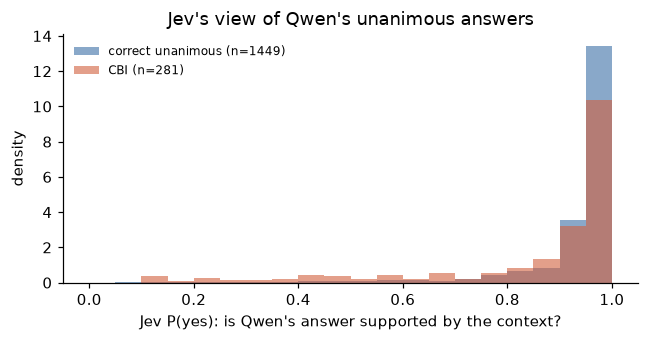

In [22]:
cbi10, ok10 = u10[u10["wrong_num"]], u10[~u10["wrong_num"]]
dist = pd.DataFrame({
    "correct unanimous": {"n": len(ok10), "median P(supported)": ok10["p_q1"].median(),
                          "share ≥ 0.9": (ok10["p_q1"] >= 0.9).mean(), "share < 0.5": (ok10["p_q1"] < 0.5).mean()},
    "CBI (confidently wrong)": {"n": len(cbi10), "median P(supported)": cbi10["p_q1"].median(),
                                "share ≥ 0.9": (cbi10["p_q1"] >= 0.9).mean(), "share < 0.5": (cbi10["p_q1"] < 0.5).mean()}}).T
display(dist.round(3))
fig, ax = plt.subplots(figsize=(6, 3.2))
bins = np.linspace(0, 1, 21)
ax.hist(ok10["p_q1"], bins=bins, density=True, alpha=0.6, color="#3b6ea5", label=f"correct unanimous (n={len(ok10)})")
ax.hist(cbi10["p_q1"], bins=bins, density=True, alpha=0.6, color="#d1603d", label=f"CBI (n={len(cbi10)})")
ax.set_xlabel("Jev P(yes): is Qwen's answer supported by the context?")
ax.set_ylabel("density")
ax.legend(frameon=False, fontsize=8)
ax.set_title("Jev's view of Qwen's unanimous answers")
fig.tight_layout()
fig.savefig(FIG_DIR / "sc_jev_on_qwen.pdf", bbox_inches="tight")
plt.show()

In [23]:
lab = lambda v, yes, no: np.where(v >= 0.5, yes, no)
joint = pd.crosstab(pd.Series(lab(cbi10["R"], "gold judged supported", "gold judged NOT supported"), name="Jev on the gold (R)"),
                    pd.Series(lab(cbi10["p_q1"], "Qwen's answer judged supported", "Qwen's answer judged NOT supported"), name="Jev on Qwen's answer"),
                    margins=True)
display(joint)
display(pd.crosstab([cbi10["dataset"], pd.Series(lab(cbi10["R"], "gold supported", "gold not supported"), index=cbi10.index, name="gold")],
                    pd.Series(lab(cbi10["p_q1"], "Qwen supported", "Qwen not supported"), index=cbi10.index, name="Qwen")))
side = cbi10[(cbi10["R"] < 0.5) & (cbi10["p_q1"] >= 0.5)]
print(f"CBI items where Jev sides with Qwen against the gold: {len(side)} ({len(side) / len(cbi10):.0%} of CBI) — "
      f"FinQA {int((side['dataset'] == 'finqa').sum())}, TAT-QA {int((side['dataset'] == 'tatqa').sum())}; arith {int((side['answer_type'] == 'arith').sum())}")
display(side.join(items[["question"]])[["dataset", "answer_type", "question", "gold_answer", "stated_answer", "R", "p_q1"]]
            .rename(columns={"stated_answer": "Qwen's answer", "R": "Jev on gold", "p_q1": "Jev on Qwen"}).head(8))

Jev on Qwen's answer,Qwen's answer judged NOT supported,Qwen's answer judged supported,All
Jev on the gold (R),,,
gold judged NOT supported,14,90,104
gold judged supported,14,163,177
All,28,253,281


Qwen                        Qwen not supported  Qwen supported
dataset gold                                                  
finqa   gold not supported                  11              72
        gold supported                       5              68
tatqa   gold not supported                   3              18
        gold supported                       9              95

CBI items where Jev sides with Qwen against the gold: 90 (32% of CBI) — FinQA 72, TAT-QA 18; arith 85


,dataset,answer_type,question,gold_answer,Qwen's answer,Jev on gold,Jev on Qwen
item_id,,,,,,,
finqa:AAP/2011/page_16.pdf-4,finqa,arith,what was the average annual store closure from 2007 to 2011?,10.5,19.8,0.08,0.92
finqa:AAPL/2010/page_42.pdf-2,finqa,arith,by how much did total other income and expense decrease from 2008 to 2009?,47.4%,$294 million,0.24,1.00
finqa:AAPL/2012/page_24.pdf-2,finqa,arith,what was the cumulative total return on the s&p 500 between september 30 2007 and sept...,5,$105,0.24,0.96
finqa:AES/2003/page_168.pdf-3,finqa,arith,what was the average dividend or cash dividends received from consolidated subsidiarie...,18.8,425,0.08,0.98
finqa:AES/2003/page_93.pdf-1,finqa,arith,what was the difference in millions in liabilities related to asset retirement obligat...,14,0,0.46,0.65
finqa:AMAT/2016/page_32.pdf-2,finqa,arith,what is the total return if 1000000 is invested in s&p500 in 2011 and sold in 2012?,152100,1152100,0.44,0.95
finqa:AMT/2005/page_32.pdf-1,finqa,arith,based on the information what was the number of stock warrants issued for the purchase...,0.06,1.0 million,0.04,0.92
finqa:AON/2007/page_184.pdf-2,finqa,arith,what is the rent expense reported in the financial statement of 2007?,408,$368 million,0.06,0.98


In [24]:
art = u10[u10["wrong_em"] & ~u10["wrong_f1"]]
clear = u10[u10["wrong_f1"]]
arte = pd.DataFrame({
    "correct (all scorings)": {"n": len(ok10[~ok10["wrong_em"]]), "median Jev P(supported)": ok10.loc[~ok10["wrong_em"], "p_q1"].median()},
    "likely scoring artefact (wrong by exact match only)": {"n": len(art), "median Jev P(supported)": art["p_q1"].median()},
    "clear error (wrong under every scoring)": {"n": len(clear), "median Jev P(supported)": clear["p_q1"].median()}}).T
display(arte.round(3))
print(f"Jev P(supported) ≥ 0.9 for {(art['p_q1'] >= 0.9).mean():.0%} of likely scoring artefacts, against "
      f"{(clear['p_q1'] >= 0.9).mean():.0%} of clear errors.")

,n,median Jev P(supported)
correct (all scorings),1422.0,0.98
likely scoring artefact (wrong by exact match only),63.0,0.98
clear error (wrong under every scoring),245.0,0.95


Jev P(supported) ≥ 0.9 for 89% of likely scoring artefacts, against 65% of clear errors.


### 10.4 Findings

**1. Jev does not close the CBI blind spot when it judges the model's own answer.**
- **Primary metric:** separating correct unanimous answers from confident errors gives **AUROC 0.62** (FinQA 0.59, TAT-QA 0.65; Q1′ and the other scorings give 0.60–0.64). That is better than the 0.5 of any agreement-based signal, but weak.
- **Jev endorses most confident errors:** about **two thirds of Qwen's CBI answers get P(supported) ≥ 0.9** from Jev. The median is 0.96, barely below the 0.98 of correct answers.

The confident errors are not just self-consistent: they also look plausible to an independent, calibrated judge.

**2. Jev is much better at judging the gold than at judging the model.**
- **Same items, two questions:** on the same unanimous items, Jev's judgment of the **gold** separates reliable items from CBI with AUROC 0.75, against **0.62** for its judgment of **Qwen's answer**.
- **FinQA, the starkest case:** 0.86 on the gold against 0.59 on Qwen's answer.
- **The pattern:** Jev doubts the gold on many CBI items, yet accepts Qwen's competing answer.
- **The exception is lookup items.** There, judging Qwen's answer separates better (0.65–0.67) than judging the gold (0.55). Jev's strength on the gold comes from arithmetic items (0.86), where it can doubt a computed gold value. For free-text spans, a competing span from the same context is hard for it to rule out either way.

**3. Jev mostly agrees with the model, not with the gold, on confident disagreements.** Within the 281 CBI items:

| Jev's verdicts | Items | Share |
|---|---|---|
| Both the gold and Qwen's answer judged supported | 163 | 58% |
| **Only Qwen's answer judged supported** | **90** | **32%** |
| Only the gold judged supported: a clean catch of Qwen's error | 14 | 5% |
| Neither judged supported | 14 | 5% |

Jev therefore catches very few confident errors outright. In about a third of cases, two independent models, the generator (Qwen) and the judge (Jev), converge on an answer that differs from the verified gold.

**4. Many "confident errors" may not be model errors.** The example rows above (the first few of the 90 items where Jev sides with Qwen against the gold) are mostly FinQA arithmetic, and several look like **item problems rather than model mistakes**:
- **Ambiguous questions:** "by how much did total other income decrease": the gold is a percentage, Qwen's answer a dollar amount. "What is the total return if 1,000,000 is invested": the gold is the gain, Qwen's answer the final value.
- **Gold values that look off in scale or definition.**

This is qualitative, from a handful of rows, and must be confirmed by the hand audit. It matches the reading that part of the CBI mass is **under-determined questions or questionable gold labels**. That is exactly what the thesis's determinacy and reliability constructs are meant to capture, and a reason for the CBI rate on verified datasets to be read with care.

**5. Jev confirms that the span-scoring artefacts are not real errors.** Answers that exact match rejects but numeric or near-verbatim matching accepts get Jev's median P(supported) of 0.98, indistinguishable from correct answers; 89% score ≥ 0.9. Clear errors get a median of 0.95, and 65% score ≥ 0.9. This is independent, semantic support for counting numerically equivalent spans as correct (blocking question 5).

### 10.5 Conclusions

**For Thread 2 (consistency–accuracy dissociation):**
- **An agreement-free judge doesn't remove the residual.** A calibrated judge that never sees other samples recovers only a small part of the CBI quadrant (AUROC 0.62). Confident errors are largely judged supported. This extends the paper's convergence finding from *generator–generator* agreement (GPT and Claude sharing wrong answers) to **generator–judge** agreement: the judge tends to share the generator's confident wrong answers.
- **It strengthens the paper's practical conclusion.** CBI is a stable residual that neither more sampling, nor cross-model ensembling, nor an LLM judge of the output reliably removes. Ground-truth labels, or a judge with access to them, remain necessary to estimate it.
- **There's a constructive angle.** Where gold labels exist, Jev judging the gold (R) separates CBI well, especially on FinQA (0.86). So a judge is useful for **auditing labelled data**, not for certifying unlabelled model outputs.

**For this paper (implication-weighted data selection):**
- **R measures what the thesis needs.** It is a judgment about a training example's *label* (P(datum is true)). It is not a general detector of model errors. §10 shows the two differ sharply: Jev judges gold labels much better than it judges a model's confident answers. That supports using R as a **data-selection gate**, which is its role in the thesis, and cautions against reading R as a model-output verifier.
- **A ready-made audit list.** The 90 CBI items where Jev sides with Qwen against the verified gold are the natural first targets for the planned hand audit (§9.1, item 2). They are disproportionately FinQA arithmetic. They are either cases where two models share a computation error, or items whose verified program and question are themselves questionable. Either answer matters: the first for Thread 2, the second for the reliability construct.

**For the span-scoring decision:** Jev's verdicts independently support treating numerically equivalent spans as correct.

### 10.6 Limitations

1. **Jev may share Qwen's biases.** TypeSafe has not said whether Jev is built on a Qwen model. If it is, generator–judge convergence is partly shared training, and the weak AUROC partly reflects that. A judge from a different family would separate the two explanations. The other session's judge-comparison work could provide one.
2. **The modal answer is from exact-match clustering.** Qwen's "modal answer" groups samples by the pipeline's matcher. Under unanimity every sample is identical, so this does not affect the primary metric.
3. **"CBI" depends on the gold.** Items where Jev sides with Qwen may be gold-label problems rather than model errors. The analysis cannot separate the two without the hand audit.
4. **One judge, one run, single scoring,** with probabilities rounded to 0.01 (determinism tolerance 0.017; see the battery notebook).
5. **Exploratory.** The design was pre-specified (§10.3) but is not one of the paper's pre-registered hypotheses, and no gate reads it.